# Кампания r3: сравнение three.js и react-three-fiber

**Вопрос исследования.** Сколько стоит react-three-fiber (R3F) по сравнению с
«чистым» three.js и какие способы писать на R3F дешёвые, а какие дорогие.

**Что сделано до этого ноутбука.** Стенд нарисовал одну и ту же сцену разными
способами (вариантами) и записал сырые замеры: длительность каждого кадра,
время каждого клика, отметки времени загрузки. Пилот определил, сколько
повторов нужно (`pilot.ipynb`), основная кампания их сняла. Здесь из сырых
замеров получаются выводы: какой вариант медленнее three.js, насколько, и
насколько мы в этом уверены.

Ноутбук реализует правила `docs/ANALYSIS.md`, раздел 4. По открытым вопросам
раздела 5 приняты предложенные там варианты (отношение средних
геометрических, бутстреп и перестановочный тест, время CPU для WebKit S2,
ранговое сравнение для неопределённой ёмкости S5).

### Как читать ноутбук

Ноутбук идёт сверху вниз: данные → одно число на каждый прогон → сравнение
вариантов → выводы по сценариям → сравнение платформ → качество данных.
Каждый раздел начинается с объяснения, *зачем* он нужен. Код можно не
читать: всё важное — в таблицах, на рисунках и в тексте.

### Словарь

| Термин | Что значит |
|---|---|
| **вариант** | способ нарисовать сцену: `threejs` — эталон; `r3f-ref`, `r3f-state` … — разные способы на R3F |
| **прогон** | одно открытие страницы с одним вариантом: 30 секунд кадров, серия кликов или одна холодная загрузка |
| **платформа** | компьютер + браузер, например «Mac · Chromium» |
| **ячейка** | платформа × сценарий × вариант (× точка нагрузки в S1); в ячейке 10–45 прогонов |
| **метрика прогона** | одно число, которым описывается прогон: например, среднее время кадра |
| **R** | во сколько раз метрика варианта больше, чем у three.js: R = 1,08 → «на 8% больше» |
| **доверительный интервал** | диапазон, в котором с высокой уверенностью лежит истинное R; чем уже, тем точнее измерение |
| **δ (порог)** | разница, которую мы считаем практически важной: 5% или 10% |
| **p-значение** | насколько вероятно получить такую разницу случайно, если на самом деле разницы нет; меньше 0,05 → разница, скорее всего, настоящая |

## 0. Подготовка

Библиотеки: **pandas** — таблицы, **numpy** — вычисления, **matplotlib** —
графики, **scipy.stats** — готовые статистические методы (бутстреп,
перестановочный тест, ранговая корреляция), **statsmodels** — поправка Холма
и интервал для доли. Сами методы с нуля не пишутся: используются проверенные
реализации этих библиотек.

Все случайные процедуры (бутстреп, перестановки) запускаются с
фиксированным зерном `SEED`, поэтому при повторном запуске ноутбук даёт
те же числа до последнего знака.

In [1]:
import json
import math
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

RESULTS = Path.cwd().parent / "results"
CAMPAIGN = "r3"          # какие серии берём: папки «r3 <время>»
REFERENCE = "threejs"    # эталон, с которым сравниваются все варианты R3F
N_RESAMPLES = 10_000     # повторов в бутстрепе и перестановочном тесте
SEED = 20261020          # зерно случайности — для воспроизводимости

# Порядок, в котором платформы и варианты идут в таблицах и на рисунках
PLATFORMS = ["Mac · Chromium", "Mac · Firefox", "Mac · WebKit", "Windows · Chromium", "Windows · Firefox"]
VARIANTS = ["threejs", "r3f", "r3f-ref", "r3f-ref-central", "r3f-state", "r3f-parent-state", "r3f-events"]
DEVICE_NAME = {"apple-m4": "Mac", "amd-ryzen-5-3550h": "Windows"}
BROWSER_NAME = {"chromium": "Chromium", "firefox": "Firefox", "webkit": "WebKit"}

# Стиль графиков — как в pilot.ipynb: приглушённые оси и сетка
INK, MUTED, GRID, SURFACE = "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]  # цвета категорий, по порядку
mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.size": 9, "axes.edgecolor": GRID, "axes.labelcolor": INK, "axes.titlesize": 10,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "legend.frameon": False,
})
pd.set_option("display.max_rows", 200, "display.width", 200, "display.max_colwidth", 60)

In [2]:
def in_order(df):
    # Сортирует таблицу в привычном порядке: платформа → точка → вариант
    df = df.copy()
    keys = []
    if "платформа" in df:
        df["_p"] = df["платформа"].map(PLATFORMS.index)
        keys.append("_p")
    if "сценарий" in df:
        keys.append("сценарий")
    if "точка" in df:
        keys.append("точка")
    if "вариант" in df:
        df["_v"] = df["вариант"].map(VARIANTS.index)
        keys.append("_v")
    return df.sort_values(keys).drop(columns=["_p", "_v"], errors="ignore").reset_index(drop=True)


def pct(r):
    # Отношение → изменение в процентах: 1.083 → «+8.3%»
    return f"{(r - 1) * 100:+.1f}%"


def figure_title(fig, text):
    fig.suptitle(text, x=0.01, ha="left", fontsize=10, fontweight="bold")

## 1. Данные кампании и их допуск

Каждая **серия** — это все прогоны одного сценария на одной платформе
(например, «S2 на Mac · Chromium»). Про серию стенд пишет служебный файл
`manifest.json`: когда снята, на каком коде, прошла ли проверку сцен.

Прежде чем что-то считать, проверяем, что серии можно доверять (правило 4.1).
Серия допускается, если:

- **завершена** — съёмка не прервалась на середине;
- **код чистый** — снята на закоммиченной версии стенда (её можно
  восстановить и повторить);
- **паритет** — перед серией стенд убедился, что все варианты рисуют одну и
  ту же сцену (те же объекты, свет, камера, кадр). Иначе сравнивались бы
  разные сцены, а не способы их рисовать;
- **все прогоны** — в каждой ячейке ровно столько прогонов, сколько
  запланировано.

Кроме того, все серии одной платформы должны быть сняты на одном коммите.

Отдельные прогоны допущенной серии **не выбрасываются** — даже «странные»
(правило 1.6): необычный прогон — тоже результат, а отбор по значению
незаметно подгоняет выводы под ожидания.

In [3]:
series = []
for path in sorted(RESULTS.glob(f"*/*/*/{CAMPAIGN} */manifest.json")):
    device, browser, scenario = path.relative_to(RESULTS).parts[:3]
    m = json.loads(path.read_text())
    cells = pd.Series([(r["variant"], r.get("load", "-")) for r in m["runs"]]).value_counts()
    series.append({
        "платформа": f"{DEVICE_NAME[device]} · {BROWSER_NAME[browser]}",
        "сценарий": scenario,
        "браузер": m["browser"]["version"],
        "коммит": m["code"]["commit"][:7],
        "завершена": m["finished"] is not None,
        "код чистый": m["code"]["clean"],
        "паритет": m["parity"]["ok"],
        "все прогоны": bool((cells == m["settings"]["repeats"]).all()),
        "ячеек": len(cells),
        "прогонов в ячейке": m["settings"]["repeats"],
        "сбоев браузера": len(m["retries"]),
        "dir": path.parent,
        "manifest": m,
    })

SERIES = in_order(pd.DataFrame(series))
SERIES["допущена"] = SERIES[["завершена", "код чистый", "паритет", "все прогоны"]].all(axis=1)
display(SERIES.drop(columns=["dir", "manifest"]))

commits = SERIES.groupby("платформа")["коммит"].nunique()
assert (commits == 1).all(), "серии одной платформы сняты на разных коммитах"
rejected = SERIES[~SERIES["допущена"]]
SERIES = SERIES[SERIES["допущена"]].reset_index(drop=True)
display(Markdown(
    f"Допущено серий: **{len(SERIES)} из {len(SERIES) + len(rejected)}**. "
    f"Коммит стенда: {', '.join(SERIES['коммит'].unique())}. "
    + ("Не допущены: " + ", ".join(rejected["платформа"] + " · " + rejected["сценарий"]) if len(rejected) else "Недопущенных серий нет.")
))

,платформа,сценарий,браузер,коммит,завершена,код чистый,паритет,все прогоны,ячеек,прогонов в ячейке,сбоев браузера,допущена
0,Mac · Chromium,s1,153.0.8010.12,4c2af05,True,True,True,True,6,10,0,True
1,Mac · Chromium,s2,153.0.8010.12,4c2af05,True,True,True,True,5,30,0,True
2,Mac · Chromium,s3,153.0.8010.12,4c2af05,True,True,True,True,2,45,0,True
3,Mac · Chromium,s4,153.0.8010.12,4c2af05,True,True,True,True,3,15,0,True
4,Mac · Chromium,s5,153.0.8010.12,4c2af05,True,True,True,True,2,29,0,True
5,Mac · Firefox,s1,155.0,4c2af05,True,True,True,True,6,10,0,True
6,Mac · Firefox,s2,155.0,4c2af05,True,True,True,True,5,30,0,True
7,Mac · Firefox,s3,155.0,4c2af05,True,True,True,True,2,45,0,True
8,Mac · Firefox,s4,155.0,4c2af05,True,True,True,True,3,15,0,True
9,Mac · Firefox,s5,155.0,4c2af05,True,True,True,True,2,29,0,True


Допущено серий: **23 из 23**. Коммит стенда: 4c2af05. Недопущенных серий нет.

## 2. Одно число на прогон

### Почему не считать каждый кадр отдельным наблюдением

За 30 секунд прогона записываются тысячи кадров. Соблазнительно сравнить
варианты по этим тысячам — но соседние кадры одного прогона **похожи друг на
друга**: у них общий прогрев JIT-компилятора, общее состояние памяти, общая
частота процессора в эти секунды. Тысяча кадров одного прогона — это не
тысяча независимых опытов, а примерно один опыт, записанный подробно.
Если считать их независимыми, статистика сочтёт разброс в десятки раз меньше
настоящего, и любая мелочь покажется «значимой».

Поэтому **единица анализа — прогон** (правило 1.2): из каждого прогона
берётся одно число, и все сравнения ведутся по этим числам. Прогоны
действительно независимы: каждый — новое открытие страницы, а варианты
снимались вперемешку в случайном порядке.

### Какое число берём (раздел 2 ANALYSIS.md)

| Сценарий | Что измеряет | Главная метрика прогона | Дополнительные | Объяснение (фазы) |
|---|---|---|---|---|
| S1 | нагрузка на видеокарту | среднее время кадра | медиана и p99 кадра | логика, отрисовка на CPU, вне фаз, GPU |
| S2 | нагрузка на процессор | среднее время кадра (WebKit — время CPU на кадр, раздел 7) | медиана и p99 кадра | то же |
| S3 | холодный старт | время до первого кадра | — | загрузка кода, построение сцены, первая отрисовка |
| S4 | отклик на клик | медиана задержки по попавшим кликам | p95 задержки | очередь, обработка, обновление React, ожидание кадра, отрисовка |
| S5 | масштабируемость | ёмкость при 60 и при 30 FPS | — | — |

Пояснения:

- **Среднее время кадра** — это пропускная способность: сколько кадров
  отрисовано за 30 с. FPS = 1000 / среднее. Медиана («типичный кадр»)
  дополнительна: в пилоте она оказалась неустойчивой, когда кадры
  чередуются короткий-длинный.
- **p99** — время, которое превышают 1% самых долгих кадров. Это мера
  «рывков».
- **Фазы кадра**: *логика* — код анимации; *отрисовка на CPU* — работа
  `renderer.render()` на процессоре; *вне фаз* — всё остальное между
  кадрами (работа React вне кадра, сборка мусора, ожидание); *GPU* — время
  работы видеокарты (только Chromium; идёт параллельно с CPU).
- **Задержка клика** — от момента, когда браузер создал событие, до конца
  отрисовки кадра, в котором виден отклик. Берётся медиана, а не среднее:
  клик приходит в случайный момент кадра, а редкие клики попадают на сборку
  мусора — медиана описывает типичный отклик, p95 — редкие долгие.
- **Ёмкость S5** — сколько объектов вариант выдерживает, не опускаясь ниже
  60 (или 30) FPS. Число объектов растёт ступенями ×√2; ёмкость находится
  между двумя ступенями, где FPS пересекает порог (интерполяция в
  логарифмических координатах, где эта зависимость почти прямая).

In [4]:
def frame_metrics(df):
    # S1, S2: строка CSV = кадр
    frame, update, render = df["frame_ms"], df["update_ms"], df["render_ms"]
    return {
        "кадр, среднее": frame.mean(),
        "кадр, медиана": frame.median(),
        "кадр, p99": np.percentile(frame, 99),
        "логика": update.mean(),
        "отрисовка CPU": render.mean(),
        "вне фаз": (frame - update - render).mean(),
        "CPU на кадр": (update + render).mean(),
        "GPU": df["gpu_ms"].mean(),            # пустые значения (замер не успел, не Chromium) пропускаются
        "доля кадров с GPU": df["gpu_ms"].notna().mean(),
    }


def start_metrics(df):
    # S3: одна строка на прогон, отметки времени от открытия страницы
    t = df.iloc[0]
    return {
        "время до первого кадра": t["render_end_ms"],
        "загрузка кода": t["code_ready_ms"],
        "построение сцены": t["render_start_ms"] - t["code_ready_ms"],
        "первая отрисовка": t["render_end_ms"] - t["render_start_ms"],
    }


def click_metrics(df):
    # S4: строка CSV = клик; считаются только клики, попавшие в объект (outcome = ok)
    ok = df[df["outcome"] == "ok"]
    latency = ok["render_end_ms"] - ok["event_ms"]
    color_ready = np.maximum(ok["applied_ms"], ok["handler_end_ms"])  # цвет готов и обработчики закончились
    return {
        "задержка, медиана": latency.median(),
        "задержка, p95": np.percentile(latency, 95),
        "очередь": (ok["handler_start_ms"] - ok["event_ms"]).median(),
        "обработка": (ok["handler_end_ms"] - ok["handler_start_ms"]).median(),
        "обновление React": (ok["applied_ms"] - ok["handler_end_ms"]).clip(lower=0).median(),
        "ожидание кадра": (ok["render_start_ms"] - color_ready).median(),
        "отрисовка": (ok["render_end_ms"] - ok["render_start_ms"]).median(),
        "кликов": len(df),
        "доля промахов": (df["outcome"] == "miss").mean(),
        "доля прочих исходов": (~df["outcome"].isin(["ok", "miss"])).mean(),
    }


def level_fps(df):
    # S5: FPS каждой ступени = 1000 / медиана времени кадра на этой ступени
    return 1000 / df.groupby("objects")["frame_ms"].median()


def capacity(fps, threshold):
    # Число объектов, при котором FPS опускается до порога. fps — Series: число объектов → FPS
    n, f = fps.index.to_numpy(), fps.to_numpy()
    for i in range(len(f) - 1):
        if f[i] >= threshold > f[i + 1]:
            u = (math.log(threshold) - math.log(f[i])) / (math.log(f[i + 1]) - math.log(f[i]))
            return math.exp(math.log(n[i]) + u * (math.log(n[i + 1]) - math.log(n[i])))
    # Порог не пересечён на пройденных ступенях: 0 — «ниже порога уже на первой», inf — «не опустился ни разу»
    return 0.0 if f[0] < threshold else math.inf

In [5]:
rows, levels = [], []
for _, s in SERIES.iterrows():
    scenario = s["сценарий"]
    for r in s["manifest"]["runs"]:
        df = pd.read_csv(s["dir"] / r["file"])
        row = {
            "платформа": s["платформа"], "сценарий": scenario, "вариант": r["variant"],
            "точка": r.get("load", "-"), "повтор": r["repeat"],
            "номер": int(Path(r["file"]).name[:3]),   # порядковый номер прогона в серии
        }
        if scenario in ("s1", "s2"):
            row.update(frame_metrics(df))
        elif scenario == "s3":
            row.update(start_metrics(df))
        elif scenario == "s4":
            row.update(click_metrics(df))
        else:
            fps = level_fps(df)
            row["ёмкость при 60 FPS"] = capacity(fps, 60)
            row["ёмкость при 30 FPS"] = capacity(fps, 30)
            for objects, value in fps.items():
                levels.append({"платформа": s["платформа"], "вариант": r["variant"], "повтор": r["repeat"],
                               "объектов": objects, "FPS": value})
        rows.append(row)

RUNS = in_order(pd.DataFrame(rows))      # одна строка = один прогон
LEVELS = pd.DataFrame(levels)            # S5: одна строка = одна ступень одного прогона

display(Markdown(f"Прогонов: **{len(RUNS)}**, ячеек: {RUNS.groupby(['платформа', 'сценарий', 'вариант', 'точка']).ngroups}."))
display(RUNS.groupby(["сценарий", "платформа"]).size().unstack().fillna(0).astype(int))

Прогонов: **1897**, ячеек: 82.

платформа,Mac · Chromium,Mac · Firefox,Mac · WebKit,Windows · Chromium,Windows · Firefox
сценарий,,,,,
s1,60,60,0,60,60
s2,150,150,150,150,150
s3,90,90,90,90,90
s4,45,45,45,45,45
s5,58,58,0,58,58


In [6]:
def mean_log_diff(a, b, axis=-1):
    # Разность средних логарифмов: exp от неё — это R
    return np.mean(a, axis=axis) - np.mean(b, axis=axis)


def compare(x, ref):
    # Сравнение прогонов варианта x с прогонами three.js ref: R, интервалы, p-значение
    x, ref = np.asarray(x, float), np.asarray(ref, float)
    if not (np.isfinite(x).all() and np.isfinite(ref).all() and (x > 0).all() and (ref > 0).all()):
        # Неопределённая ёмкость S5 (0 или inf): отношение не считается, сравнение по рангам
        p = stats.mannwhitneyu(x, ref).pvalue
        return {"R": np.nan, "95% от": np.nan, "95% до": np.nan, "90% от": np.nan, "90% до": np.nan,
                "p": p, "по рангам": True}

    a, b = np.log(x), np.log(ref)
    # Бутстреп: прогоны варианта и three.js независимо выбираются с возвращением
    boot = stats.bootstrap((a, b), mean_log_diff, n_resamples=N_RESAMPLES,
                           rng=np.random.default_rng(SEED))
    lo95, hi95, lo90, hi90 = np.percentile(boot.bootstrap_distribution, [2.5, 97.5, 5, 95])
    # Перестановочный тест: метки «вариант / three.js» перемешиваются между прогонами
    perm = stats.permutation_test((a, b), mean_log_diff, permutation_type="independent",
                                  n_resamples=N_RESAMPLES, rng=np.random.default_rng(SEED))
    return {"R": math.exp(mean_log_diff(a, b)),
            "95% от": math.exp(lo95), "95% до": math.exp(hi95),
            "90% от": math.exp(lo90), "90% до": math.exp(hi90),
            "p": perm.pvalue, "по рангам": False}


def verdict(row):
    # Вывод по правилам раздела 3.4
    if row["по рангам"]:
        return "различие (по рангам)" if row["p (Холм)"] < 0.05 else "не ясно"
    delta = row["δ"]
    equivalent = 1 / (1 + delta) <= row["90% от"] and row["90% до"] <= 1 + delta
    differs = not (row["95% от"] <= 1 <= row["95% до"])
    if equivalent and not differs:
        return "≈ равны"
    if equivalent:
        return f"≈ равны, разница {pct(row['R'])}"
    if differs and row["p (Холм)"] < 0.05:
        word = "больше" if row["R"] > 1 else "меньше"
        return f"{word} на {abs(row['R'] - 1) * 100:.1f}%"
    return "не ясно"


def for_r3f(row):
    # «больше/меньше» → «хуже/лучше» для R3F
    if not row["вывод"].startswith(("больше", "меньше")):
        return ""
    bigger = row["вывод"].startswith("больше")
    return "лучше" if bigger == (row["метрика"] in HIGHER_IS_BETTER) else "хуже"

### Проверка A/A для допуска данных

A/A-тест — диагностическая проверка анализа, а не дополнительное сравнение
вариантов. Внутри каждой ячейки (платформа × сценарий × вариант × точка)
прогоны случайно делятся на две группы и сравниваются теми же средними
логарифмами и перестановочным тестом, что используются ниже. При отсутствии
систематической разницы доля `p < 0,05` должна быть около 5%.

Тест не исключает отдельные прогоны или серии. Он только показывает, не даёт
ли текущая выборка и процедура анализа избыток ложных срабатываний. Для
нечётного числа прогонов (S5 — 29) одна случайная запись не используется в
конкретном разбиении; размер каждой половины указан в результате.


In [7]:
AA_SPLITS = 200
AA_PERMUTATIONS = 2_000
AA_SEED = 20261027

# Главные метрики — те же, что в основном анализе; формулы уже применены при
# построении RUNS выше из frame_metrics/start_metrics/click_metrics/capacity.
AA_MAIN = {
    "s1": ["кадр, среднее"],
    "s2": ["кадр, среднее"],
    "s3": ["время до первого кадра"],
    "s4": ["задержка, медиана"],
    "s5": ["ёмкость при 60 FPS", "ёмкость при 30 FPS"],
}

# В WebKit частота кадров ограничена экраном; для S2 проверяется CPU на кадр.
def aa_metrics_for(platform, scenario):
    if platform == "Mac · WebKit" and scenario == "s2":
        return ["CPU на кадр"]
    return AA_MAIN[scenario]


aa_rng = np.random.default_rng(AA_SEED)
aa_rows = []
for (platform, scenario, variant, point), cell in RUNS.groupby(
    ["платформа", "сценарий", "вариант", "точка"]
):
    for metric in aa_metrics_for(platform, scenario):
        values = pd.to_numeric(cell[metric], errors="coerce").to_numpy(float)
        values = values[np.isfinite(values) & (values > 0)]
        n = len(values)
        half = n // 2
        if half < 2:
            aa_rows.append({"платформа": platform, "сценарий": scenario, "вариант": variant,
                            "точка": point, "метрика": metric, "n": n,
                            "n в половине": half, "s, %": np.nan, "MDE, %": np.nan,
                            "|R−1| A/A, медиана %": np.nan, "доля p<0,05": np.nan,
                            "недостаточно данных": True})
            continue

        log_values = np.log(values)
        s = log_values.std(ddof=1)
        # Верхняя граница 80%-го интервала для разброса (ANALYSIS.md, раздел 3).
        s_upper = s * np.sqrt((n - 1) / stats.chi2.ppf(0.2, n - 1))
        mde = np.exp((1.96 + 0.84) * s_upper * np.sqrt(2 / half)) - 1
        ratios, pvalues = [], []
        for _ in range(AA_SPLITS):
            shuffled = aa_rng.permutation(log_values)
            a, b = shuffled[:half], shuffled[-half:]
            ratios.append(np.exp(mean_log_diff(a, b)) - 1)
            permutation = stats.permutation_test(
                (a, b), mean_log_diff, permutation_type="independent",
                n_resamples=AA_PERMUTATIONS, rng=aa_rng,
            )
            pvalues.append(permutation.pvalue)
        aa_rows.append({"платформа": platform, "сценарий": scenario, "вариант": variant,
                        "точка": point, "метрика": metric, "n": n,
                        "n в половине": half, "s, %": 100 * s,
                        "MDE, %": 100 * mde,
                        "|R−1| A/A, медиана %": 100 * np.median(np.abs(ratios)),
                        "доля p<0,05": np.mean(np.asarray(pvalues) < 0.05),
                        "недостаточно данных": False})

AA = pd.DataFrame(aa_rows)
display(Markdown(
    f"A/A: **{len(AA)}** метрик в ячейках; средняя доля `p < 0,05` среди "
    f"достаточных ячеек: **{AA['доля p<0,05'].dropna().mean():.3f}** "
    "(ожидается около 0,05)."
))
display(AA.round(3))
display(Markdown("Сводка по сценарию:"))
display(AA.groupby("сценарий")[["s, %", "MDE, %", "|R−1| A/A, медиана %", "доля p<0,05"]]
        .agg(["median", "max"]).round(3))


A/A: **90** метрик в ячейках; средняя доля `p < 0,05` среди достаточных ячеек: **0.049** (ожидается около 0,05).

,платформа,сценарий,вариант,точка,метрика,n,n в половине,"s, %","MDE, %","|R−1| A/A, медиана %","доля p<0,05",недостаточно данных
0,Mac · Chromium,s1,r3f-ref,A,"кадр, среднее",10,5,0.959,2.220,0.421,0.050,False
1,Mac · Chromium,s1,r3f-ref,B,"кадр, среднее",10,5,0.179,0.412,0.084,0.055,False
2,Mac · Chromium,s1,r3f-ref,C,"кадр, среднее",10,5,0.991,2.296,0.498,0.060,False
3,Mac · Chromium,s1,threejs,A,"кадр, среднее",10,5,0.403,0.928,0.191,0.035,False
4,Mac · Chromium,s1,threejs,B,"кадр, среднее",10,5,0.050,0.116,0.023,0.070,False
5,Mac · Chromium,s1,threejs,C,"кадр, среднее",10,5,0.577,1.329,0.264,0.040,False
6,Mac · Chromium,s2,r3f-parent-state,-,"кадр, среднее",30,15,1.169,1.367,0.285,0.075,False
7,Mac · Chromium,s2,r3f-ref,-,"кадр, среднее",30,15,0.579,0.675,0.127,0.055,False
8,Mac · Chromium,s2,r3f-ref-central,-,"кадр, среднее",30,15,2.639,3.113,0.675,0.045,False
9,Mac · Chromium,s2,r3f-state,-,"кадр, среднее",30,15,0.816,0.952,0.207,0.060,False


Сводка по сценарию:

s, %        MDE, %         |R−1| A/A, медиана %        доля p<0,05       
         median    max median     max               median    max      median    max
сценарий                                                                            
s1        0.510  2.946  1.176   6.980                0.227  1.887       0.050  0.075
s2        1.169  6.208  1.367   7.476                0.285  2.106       0.045  0.080
s3        2.964  4.952  2.806   4.732                0.620  1.498       0.042  0.090
s4        3.616  7.461  6.803  14.544                1.404  2.814       0.055  0.060
s5        2.415  4.052  2.954   5.004                0.642  1.198       0.050  0.070

### Как выглядит один прогон

Чтобы было понятно, что именно сворачивается в «одно число», ниже — все
кадры одного прогона S2 (three.js на Mac · Chromium). Каждая точка — кадр.
Горизонтальные линии — среднее и медиана: именно среднее становится
метрикой этого прогона. Видно, что кадры колеблются вокруг устойчивого
уровня, а редкие долгие кадры («рывки») поднимают p99. Ось времени
кадра начинается не с нуля, а приближена к данным — чтобы был виден
разброс; единичные кадры выше верхнего края не показаны (их число и
максимум подписаны над графиком).

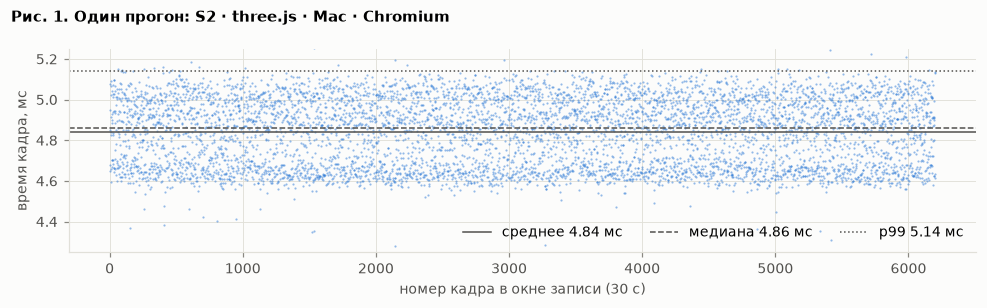

In [42]:
example = SERIES[(SERIES["платформа"] == "Mac · Chromium") & (SERIES["сценарий"] == "s2")].iloc[0]
first_run = next(r for r in example["manifest"]["runs"] if r["variant"] == REFERENCE)
frames = pd.read_csv(example["dir"] / first_run["file"])

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.scatter(frames["frame"], frames["frame_ms"], s=2, color=SERIES_COLORS[0], alpha=0.5, linewidth=0)
for value, label, style in [(frames["frame_ms"].mean(), "среднее", "-"), (frames["frame_ms"].median(), "медиана", "--"),
                            (np.percentile(frames["frame_ms"], 99), "p99", ":")]:
    ax.axhline(value, color=INK, lw=1, ls=style, label=f"{label} {value:.2f} мс")
ax.legend(loc="lower right", ncol=3)
ax.set_ylim(4.25, 5.25)
ax.set_xlabel("номер кадра в окне записи (30 с)")
ax.set_ylabel("время кадра, мс")
figure_title(fig, "Рис. 1. Один прогон: S2 · three.js · Mac · Chromium")
fig.tight_layout()
plt.show()

## 3. Как сравниваются варианты

Каждый вариант R3F сравнивается с three.js **той же платформы**, того же
сценария и той же точки нагрузки. Платформы между собой не смешиваются
(правило 1.4): на одной платформе варианты снимались вперемешку в одних
условиях, а разные машины и браузеры несопоставимы в миллисекундах.

### 3.1. Эффект: во сколько раз (R)

Нас интересует не «на сколько миллисекунд», а **«во сколько раз»**: разница
в 1 мс огромна при кадре 4 мс и незаметна при 40 мс. Эффект — отношение

$$R = \frac{\text{среднее геометрическое метрики варианта}}{\text{среднее геометрическое метрики three.js}}
= \exp\big(\overline{\ln x_\text{вариант}} - \overline{\ln x_\text{three.js}}\big)$$

R = 1,08 читается «у варианта метрика на 8% больше, чем у three.js». Для
времени кадра и задержки больше — **хуже** (медленнее), для ёмкости S5
больше — **лучше**.

*Среднее геометрическое* — среднее логарифмов, переведённое обратно. Оно
естественно для отношений («в 2 раза больше» и «в 2 раза меньше»
симметричны) и учитывает все прогоны. Медиана прогонов для этого хуже: если
прогоны ячейки делятся на два устойчивых уровня, медиана случайно
«выбирает» один из них (раздел 5).

### 3.2. Насколько мы уверены: бутстреп-интервал

Прогонов конечное число, и при другой съёмке R получилось бы немного другим.
**Доверительный интервал** показывает, в каких пределах R могло бы
оказаться. Строится он **бутстрепом** (`scipy.stats.bootstrap`): из имеющихся
прогонов варианта и прогонов three.js много раз (10 000) случайно набираются
новые выборки того же размера «с возвращением» — один прогон может попасть
дважды, другой ни разу, — и каждый раз пересчитывается R. Так мы имитируем
«а что, если бы мы сняли кампанию ещё раз». Середина получившихся R
(95% из них) — это 95%-ный интервал.

Бутстреп не требует, чтобы значения были распределены «по колоколу»
(нормально), — это важно для задержки и ёмкости.

### 3.3. Есть ли разница: перестановочный тест и поправка Холма

**p-значение** отвечает на вопрос: «если бы варианты на самом деле не
различались, как часто случайность давала бы разницу не меньше
наблюдаемой?». Считается **перестановочным тестом**
(`scipy.stats.permutation_test`): метки «вариант» и «three.js» 10 000 раз
случайно перемешиваются между прогонами, и смотрим, в какой доле
перемешиваний разница средних логарифмов по модулю не меньше настоящей.
Если почти никогда (p < 0,05) — разница, скорее всего, настоящая.

**Поправка Холма** (`statsmodels`): на одной платформе в одном сценарии
проверяется несколько гипотез (в S2 — 4 варианта против three.js). Чем
больше проверок, тем выше шанс, что хотя бы одна «выстрелит» случайно.
Поправка Холма увеличивает p-значения так, чтобы общий шанс ложной тревоги
на всю группу («семью») проверок оставался 5%. Семья — платформа × сценарий
(в S1 — × точка нагрузки); главные метрики образуют одну семью (в S5 — обе
ёмкости), каждая дополнительная метрика — свою.

### 3.4. Вывод: «равны», «больше/меньше» или «не ясно»

Статистическая значимость — не то же самое, что важность: при 45 прогонах
можно уверенно обнаружить разницу в 1%, которая никому не важна. Поэтому
есть **порог практической значимости δ**: 5% для времени кадра, старта и
ёмкости; 10% для задержки клика и хвостов (p99, p95) — они шумнее по
природе.

Варианты признаются **практически равными** (тест эквивалентности TOST),
если весь 90%-ный интервал R лежит внутри коридора [1/(1+δ); 1+δ] —
то есть даже самая неблагоприятная правдоподобная разница меньше порога.

| Вывод | Условие | Как читать |
|---|---|---|
| **≈ равны** | 90%-ный интервал внутри коридора, 95%-ный содержит 1 | разницы нет или она меньше порога |
| **≈ равны, разница X%** | 90%-ный интервал внутри коридора, 95%-ный не содержит 1 | разница есть, но меньше порога — практически несущественна |
| **больше / меньше на X%** | 95%-ный интервал не содержит 1 и выходит за коридор, p после поправки Холма < 0,05 | существенная разница |
| **не ясно** | ни одно из условий | данных недостаточно для вывода |

Колонка «для R3F» переводит «больше/меньше» в «хуже/лучше» с учётом того,
что для ёмкости больше — лучше.

In [9]:
# Какие метрики сравниваются в каждом сценарии
MAIN = {"s1": ["кадр, среднее"], "s2": ["кадр, среднее"], "s3": ["время до первого кадра"],
        "s4": ["задержка, медиана"], "s5": ["ёмкость при 60 FPS", "ёмкость при 30 FPS"]}
EXTRA = {"s1": ["кадр, медиана", "кадр, p99"], "s2": ["кадр, медиана", "кадр, p99"], "s3": [],
         "s4": ["задержка, p95"], "s5": []}

# Порог практической значимости δ каждой метрики (ANALYSIS.md, раздел 3, шаг 5)
DELTA = {
    "кадр, среднее": 0.05, "кадр, медиана": 0.05, "кадр, p99": 0.10, "CPU на кадр": 0.05,
    "время до первого кадра": 0.05, "задержка, медиана": 0.10, "задержка, p95": 0.10,
    "ёмкость при 60 FPS": 0.05, "ёмкость при 30 FPS": 0.05,
}
HIGHER_IS_BETTER = {"ёмкость при 60 FPS", "ёмкость при 30 FPS"}


def metrics_for(platform, scenario):
    # (главные, дополнительные). В WebKit кадр ограничен экраном (60 FPS), поэтому в S2
    # сравнивается время работы CPU на кадр, а время кадра не сравнивается (раздел 7)
    if platform == "Mac · WebKit" and scenario == "s2":
        return ["CPU на кадр"], []
    return MAIN[scenario], EXTRA[scenario]

Ниже — все сравнения сразу: каждый вариант R3F против three.js на каждой
платформе, по главным и дополнительным метрикам. Расчёт занимает около
минуты (по 10 000 повторов бутстрепа и перестановок на каждое сравнение).

In [10]:
rows = []
for (platform, scenario, point), cell in RUNS.groupby(["платформа", "сценарий", "точка"]):
    main, extra = metrics_for(platform, scenario)
    ref = cell[cell["вариант"] == REFERENCE]
    for variant in cell["вариант"].unique():
        if variant == REFERENCE:
            continue
        runs = cell[cell["вариант"] == variant]
        for metric in main + extra:
            role = "главная" if metric in main else "дополнительная"
            family = f"{platform} | {scenario} | {point}" + ("" if role == "главная" else f" | {metric}")
            result = compare(runs[metric], ref[metric])
            rows.append({"платформа": platform, "сценарий": scenario, "точка": point, "вариант": variant,
                         "метрика": metric, "роль": role, "δ": DELTA[metric], "n": len(runs),
                         "семья": family, **result})

COMP = in_order(pd.DataFrame(rows))
COMP["p (Холм)"] = COMP.groupby("семья")["p"].transform(lambda p: multipletests(p, method="holm")[1])
COMP["вывод"] = COMP.apply(verdict, axis=1)
COMP["для R3F"] = COMP.apply(for_r3f, axis=1)
display(Markdown(f"Сравнений: **{len(COMP)}** (главных метрик — {(COMP['роль'] == 'главная').sum()})."))

Сравнений: **121** (главных метрик — 55).

In [11]:
def show_comparisons(scenario, role="главная"):
    # Таблица сравнений сценария в читаемом виде
    c = COMP[(COMP["сценарий"] == scenario) & (COMP["роль"] == role)]
    table = pd.DataFrame({
        "платформа": c["платформа"],
        "точка": c["точка"],
        "вариант": c["вариант"],
        "метрика": c["метрика"],
        "R − 1": c["R"].map(pct),
        "95% интервал": [f"[{pct(lo)}; {pct(hi)}]" for lo, hi in zip(c["95% от"], c["95% до"])],
        "90% интервал": [f"[{pct(lo)}; {pct(hi)}]" for lo, hi in zip(c["90% от"], c["90% до"])],
        "порог δ": c["δ"].map(lambda d: f"±{d:.0%}"),
        "p (Холм)": c["p (Холм)"].map(lambda p: f"{p:.4f}"),
        "вывод": c["вывод"],
        "для R3F": c["для R3F"],
    })
    if (table["точка"] == "-").all():
        table = table.drop(columns="точка")
    display(table.reset_index(drop=True))


def geomean(values):
    return math.exp(np.mean(np.log(values)))


def row_label(scenario, point, variant, metric_index):
    parts = [point] if point != "-" else []
    parts.append(variant)
    if scenario == "s5":
        parts.append(MAIN["s5"][metric_index].replace("ёмкость при ", ""))
    return " · ".join(parts)


def set_ratio_ticks(ax):
    # Деления логарифмической шкалы в «процентах относительно three.js», не гуще ~6 на панель
    lo, hi = ax.get_xlim()
    min_step = (math.log(hi) - math.log(lo)) / 5
    candidates = [0.25, 0.5, 0.67, 0.8, 0.9, 0.95, 1.05, 1.1, 1.2, 1.5, 2, 3, 4, 6, 8]
    ticks = [1.0]
    for t in sorted(c for c in candidates if c > 1 and c < hi):
        if math.log(t) - math.log(ticks[-1]) >= min_step:
            ticks.append(t)
    for t in sorted((c for c in candidates if lo < c < 1), reverse=True):
        if math.log(ticks[0]) - math.log(t) >= min_step:
            ticks.insert(0, t)
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{(x - 1) * 100:+.0f}%"))
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda x, _: ""))


def plot_runs_and_ratio(scenario, title):
    # Точки — прогоны (относительно среднего геометрического three.js той же платформы);
    # чёрный ромб и линия — R и его 95%-ный интервал; серая полоса — коридор «практически равны»
    runs = RUNS[RUNS["сценарий"] == scenario]
    platforms = [p for p in PLATFORMS if p in set(runs["платформа"])]
    n_metrics = len(MAIN[scenario])
    lines = []   # (точка, вариант, номер метрики)
    for point in sorted(runs["точка"].unique()):
        variants = [v for v in VARIANTS if v in set(runs[runs["точка"] == point]["вариант"])]
        lines += [(point, v, k) for v in variants for k in range(n_metrics)]

    fig, axes = plt.subplots(1, len(platforms), figsize=(2.9 * len(platforms) + 1.4, 0.42 * len(lines) + 1.4),
                             sharey=True, squeeze=False)
    jitter = np.random.default_rng(SEED)
    for ax, platform in zip(axes[0], platforms):
        main, _ = metrics_for(platform, scenario)
        delta = DELTA[main[0]]
        ax.axvspan(1 / (1 + delta), 1 + delta, color=GRID, alpha=0.6, lw=0)
        ax.axvline(1, color=MUTED, lw=0.8)
        for i, (point, variant, k) in enumerate(lines):
            metric = main[k]
            here = runs[(runs["платформа"] == platform) & (runs["точка"] == point)]
            base = geomean(here.loc[here["вариант"] == REFERENCE, metric])
            values = here.loc[here["вариант"] == variant, metric] / base
            ax.scatter(values, i - 0.17 + jitter.uniform(-0.07, 0.07, len(values)), s=9,
                       color=SERIES_COLORS[0], alpha=0.55, linewidth=0)
            if variant != REFERENCE:
                c = COMP[(COMP["платформа"] == platform) & (COMP["сценарий"] == scenario) & (COMP["точка"] == point)
                         & (COMP["вариант"] == variant) & (COMP["метрика"] == metric)].iloc[0]
                ax.plot([c["95% от"], c["95% до"]], [i + 0.18, i + 0.18], color=INK, lw=2, solid_capstyle="round")
                ax.scatter([c["R"]], [i + 0.18], marker="D", s=22, color=INK, zorder=3)
                ax.text(c["95% до"], i + 0.18, "  " + pct(c["R"]), va="center", fontsize=7.5, color=INK)
        ax.set_xscale("log")
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi * (hi / lo) ** 0.25)   # место справа для подписей R
        set_ratio_ticks(ax)
        ax.set_title(platform + ("\n(CPU на кадр)" if main[0] == "CPU на кадр" else ""))
        ax.set_xlabel("относительно three.js")
    axes[0][0].set_yticks(range(len(lines)), [row_label(scenario, *line) for line in lines])
    axes[0][0].invert_yaxis()
    figure_title(fig, title)
    fig.tight_layout()
    plt.show()

In [12]:
def plot_stacked(table, parts, title, xlabel, marker=None):
    # Горизонтальные столбцы из частей (фаз) для каждой строки table, по панели на платформу.
    # marker — колонка, которая рисуется отдельной чертой поверх столбца (GPU идёт параллельно с CPU)
    platforms = [p for p in PLATFORMS if p in set(table["платформа"])]
    labels = list(dict.fromkeys(table["строка"]))
    fig, axes = plt.subplots(1, len(platforms), figsize=(2.9 * len(platforms) + 1.4, 0.36 * len(labels) + 1.6),
                             sharey=True, squeeze=False)
    for ax, platform in zip(axes[0], platforms):
        t = table[table["платформа"] == platform].set_index("строка").reindex(labels)
        left = np.zeros(len(labels))
        for color, part in zip(SERIES_COLORS, parts):
            width = t[part].fillna(0).to_numpy()
            ax.barh(range(len(labels)), width, left=left, height=0.62, color=color, edgecolor=SURFACE,
                    linewidth=1, label=part)
            left += width
        if marker is not None and t[marker].notna().any():
            ax.scatter(t[marker], range(len(labels)), marker="|", s=160, color=INK, linewidth=2, zorder=3,
                       label=marker)
        ax.set_title(platform)
        ax.set_xlabel(xlabel)
        ax.grid(axis="y", visible=False)
    axes[0][0].set_yticks(range(len(labels)), labels)
    axes[0][0].invert_yaxis()
    handles, names = axes[0][0].get_legend_handles_labels()
    for ax in axes[0][1:]:
        h, n = ax.get_legend_handles_labels()
        if len(h) > len(handles):
            handles, names = h, n
    if marker in names:   # черта GPU — последней в легенде
        k = names.index(marker)
        handles, names = handles[:k] + handles[k + 1:] + [handles[k]], names[:k] + names[k + 1:] + [names[k]]
    fig.legend(handles, names, loc="upper left", bbox_to_anchor=(0.01, 0.93), ncol=len(names))
    figure_title(fig, title)
    fig.tight_layout(rect=(0, 0, 1, 0.88))
    plt.show()


def phase_table(scenario, total, parts):
    # Медианы по прогонам ячейки: итог и его части, плюс разница «вариант − three.js»
    runs = RUNS[RUNS["сценарий"] == scenario]
    columns = [total] + parts
    med = runs.groupby(["платформа", "точка", "вариант"])[columns].median().reset_index()
    ref = med[med["вариант"] == REFERENCE].drop(columns="вариант")
    med = med.merge(ref, on=["платформа", "точка"], suffixes=("", " (three.js)"))
    for c in columns:
        med[f"Δ {c}"] = med[c] - med[f"{c} (three.js)"]
    med["строка"] = [p + " · " + v if p != "-" else v for p, v in zip(med["точка"], med["вариант"])]
    return in_order(med)


def show_phase_table(table, total, parts):
    # Абсолютные медианы, мс, и разница с three.js: в мс и в долях времени three.js
    columns = [total] + parts
    out = table[["платформа", "строка"] + columns].copy()
    for c in columns:
        out[f"Δ {c}"] = table[f"Δ {c}"]
    out[f"Δ {total}, % от three.js"] = table[f"Δ {total}"] / table[f"{total} (three.js)"] * 100
    display(out.round(2))

## 4. Результаты по сценариям

Для каждого сценария — таблица выводов, рисунок и разбор фаз.

**Как читать рисунки «прогоны и отношение».** Каждая панель — платформа,
каждая строка — вариант. Синие точки — отдельные прогоны: их метрика,
делённая на среднее геометрическое three.js той же платформы (0% — как у
three.js в среднем). Строка `threejs` показывает разброс самого эталона.
Чёрный ромб — отношение R (подписано справа), чёрная черта — его 95%-ный
интервал (часто короче ромба — тогда измерение очень точное). Серая
полоса — коридор «практически равны» (±δ). Если черта целиком в полосе —
варианты практически равны; если целиком справа от неё — вариант заметно
больше (для времени — медленнее). Шкала логарифмическая: +100% (в 2 раза
больше) и −50% (в 2 раза меньше) стоят на одинаковом расстоянии от нуля.

### 4.1. S1 — нагрузка на видеокарту

Сцена с тяжёлой работой для GPU в трёх точках нагрузки: **A** — заливка
пикселей (300 объектов, двойное разрешение, тени 4096), **B** — много вершин
(3000 объектов), **C** — много вызовов отрисовки (3000 лёгких объектов).
Сравниваются three.js и рекомендуемый вариант R3F `ref`. Ожидание: если
кадр ограничен видеокартой, «надстройка» R3F над three.js на процессоре
почти не должна сказываться на времени кадра.

,платформа,точка,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,A,r3f-ref,"кадр, среднее",-0.1%,[-0.6%; +0.6%],[-0.6%; +0.4%],±5%,0.8001,≈ равны,
1,Mac · Chromium,B,r3f-ref,"кадр, среднее",+0.2%,[+0.1%; +0.3%],[+0.1%; +0.3%],±5%,0.0052,"≈ равны, разница +0.2%",
2,Mac · Chromium,C,r3f-ref,"кадр, среднее",-0.0%,[-0.7%; +0.7%],[-0.6%; +0.6%],±5%,0.9635,≈ равны,
3,Mac · Firefox,A,r3f-ref,"кадр, среднее",+0.2%,[-0.0%; +0.4%],[+0.0%; +0.4%],±5%,0.1380,≈ равны,
4,Mac · Firefox,B,r3f-ref,"кадр, среднее",+3.0%,[+2.5%; +3.5%],[+2.6%; +3.4%],±5%,0.0002,"≈ равны, разница +3.0%",
5,Mac · Firefox,C,r3f-ref,"кадр, среднее",+2.6%,[+2.1%; +3.0%],[+2.2%; +3.0%],±5%,0.0002,"≈ равны, разница +2.6%",
6,Windows · Chromium,A,r3f-ref,"кадр, среднее",+0.1%,[-1.1%; +2.1%],[-1.0%; +1.9%],±5%,0.9895,≈ равны,
7,Windows · Chromium,B,r3f-ref,"кадр, среднее",-0.3%,[-0.6%; -0.0%],[-0.6%; -0.1%],±5%,0.0620,"≈ равны, разница -0.3%",
8,Windows · Chromium,C,r3f-ref,"кадр, среднее",+1.2%,[+0.5%; +1.9%],[+0.6%; +1.8%],±5%,0.0038,"≈ равны, разница +1.2%",
9,Windows · Firefox,A,r3f-ref,"кадр, среднее",-1.6%,[-1.9%; -1.2%],[-1.9%; -1.3%],±5%,0.0002,"≈ равны, разница -1.6%",


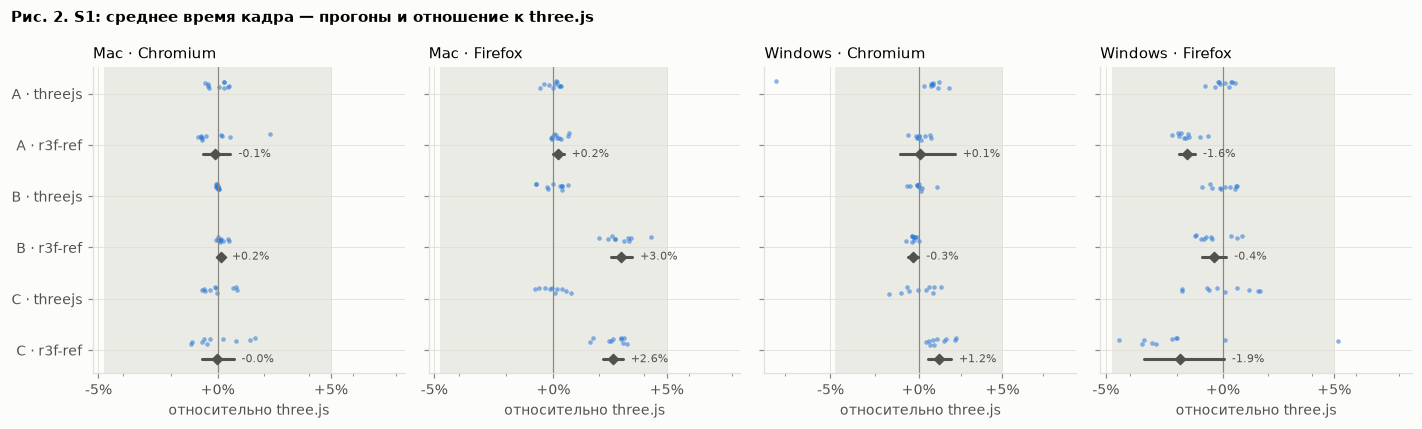

In [13]:
show_comparisons("s1")
plot_runs_and_ratio("s1", "Рис. 2. S1: среднее время кадра — прогоны и отношение к three.js")

Дополнительные метрики S1: медиана кадра (порог 5%) и p99 — «рывки»
(порог 10%).

In [14]:
show_comparisons("s1", "дополнительная")

,платформа,точка,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,A,r3f-ref,"кадр, медиана",-0.4%,[-1.2%; +0.6%],[-1.1%; +0.4%],±5%,0.4832,≈ равны,
1,Mac · Chromium,A,r3f-ref,"кадр, p99",-0.3%,[-1.0%; +0.3%],[-0.9%; +0.2%],±10%,0.3686,≈ равны,
2,Mac · Chromium,B,r3f-ref,"кадр, медиана",-0.3%,[-0.6%; +0.0%],[-0.5%; -0.0%],±5%,0.1148,≈ равны,
3,Mac · Chromium,B,r3f-ref,"кадр, p99",+0.2%,[-0.2%; +0.5%],[-0.1%; +0.5%],±10%,0.4172,≈ равны,
4,Mac · Chromium,C,r3f-ref,"кадр, медиана",-0.2%,[-0.9%; +0.6%],[-0.8%; +0.5%],±5%,0.6871,≈ равны,
5,Mac · Chromium,C,r3f-ref,"кадр, p99",+1.7%,[+0.0%; +3.7%],[+0.3%; +3.4%],±10%,0.0960,"≈ равны, разница +1.7%",
6,Mac · Firefox,A,r3f-ref,"кадр, медиана",+0.7%,[+0.6%; +0.9%],[+0.6%; +0.9%],±5%,0.0002,"≈ равны, разница +0.7%",
7,Mac · Firefox,A,r3f-ref,"кадр, p99",-3.0%,[-3.4%; -2.6%],[-3.4%; -2.7%],±10%,0.0002,"≈ равны, разница -3.0%",
8,Mac · Firefox,B,r3f-ref,"кадр, медиана",+3.0%,[+2.6%; +3.5%],[+2.6%; +3.4%],±5%,0.0002,"≈ равны, разница +3.0%",
9,Mac · Firefox,B,r3f-ref,"кадр, p99",+1.9%,[+1.4%; +2.5%],[+1.5%; +2.4%],±10%,0.0002,"≈ равны, разница +1.9%",


**Фазы S1 (правило 4.7).** Фазы объясняют, *где* тратится время кадра.
Столбец — среднее время кадра (медиана по прогонам), разбитое на логику,
отрисовку на CPU и «вне фаз». Чёрная черта — время GPU (только Chromium):
видеокарта работает параллельно с процессором, поэтому GPU не входит в сумму.
Если черта GPU близка к концу столбца — кадр ограничен видеокартой (так и
задуман S1); если намного левее — процессором.

В таблице: медианы по прогонам (мс), разница с three.js (мс) и разница
времени кадра в процентах от three.js. Фазы описательные — отдельные тесты
по ним не проводятся: они объясняют уже найденные различия.

,платформа,строка,"кадр, среднее",логика,отрисовка CPU,вне фаз,GPU,"Δ кадр, среднее",Δ логика,Δ отрисовка CPU,Δ вне фаз,Δ GPU,"Δ кадр, среднее, % от three.js"
0,Mac · Chromium,A · threejs,5.44,0.00,5.35,0.09,8.17,0.00,0.00,0.00,0.00,0.00,0.00
1,Mac · Chromium,A · r3f-ref,5.40,0.00,5.31,0.09,8.13,-0.04,0.00,-0.03,0.00,-0.03,-0.75
2,Mac · Chromium,B · threejs,18.18,0.01,18.03,0.13,21.14,0.00,0.00,0.00,0.00,0.00,0.00
3,Mac · Chromium,B · r3f-ref,18.20,0.01,18.05,0.14,21.16,0.02,0.00,0.01,0.01,0.02,0.10
4,Mac · Chromium,C · threejs,9.58,0.01,9.46,0.11,6.06,0.00,0.00,0.00,0.00,0.00,0.00
5,Mac · Chromium,C · r3f-ref,9.55,0.01,9.44,0.11,6.06,-0.03,-0.00,-0.03,0.00,0.00,-0.28
6,Mac · Firefox,A · threejs,4.01,0.01,1.01,2.98,NaN,0.00,0.00,0.00,0.00,NaN,0.00
7,Mac · Firefox,A · r3f-ref,4.02,0.01,1.15,2.86,NaN,0.00,0.00,0.14,-0.12,NaN,0.06
8,Mac · Firefox,B · threejs,17.92,0.03,16.26,1.59,NaN,0.00,0.00,0.00,0.00,NaN,0.00
9,Mac · Firefox,B · r3f-ref,18.41,0.02,16.74,1.66,NaN,0.49,-0.01,0.48,0.07,NaN,2.74


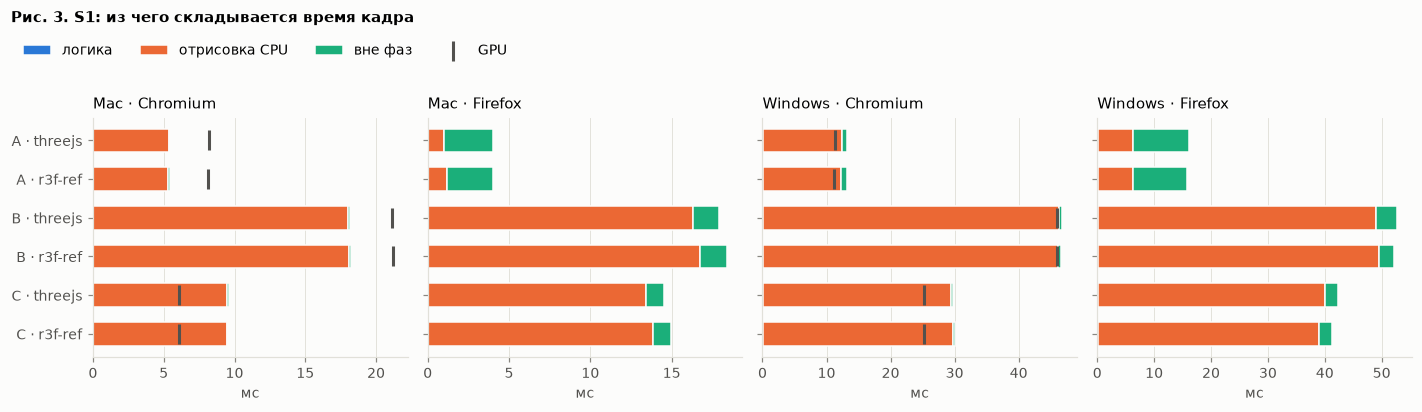

In [15]:
S12_PARTS = ["логика", "отрисовка CPU", "вне фаз"]
s1_phases = phase_table("s1", "кадр, среднее", S12_PARTS + ["GPU"])
show_phase_table(s1_phases, "кадр, среднее", S12_PARTS + ["GPU"])
plot_stacked(s1_phases, S12_PARTS, "Рис. 3. S1: из чего складывается время кадра", "мс", marker="GPU")

### 4.2. S2 — нагрузка на процессор

3000 анимированных кубов: каждый кадр обновляются позиции и повороты всех
объектов. Здесь видна цена способа управления сценой в R3F:

- `r3f-ref` — у каждого объекта свой `useFrame`, изменение через ref
  (рекомендация документации R3F);
- `r3f-ref-central` — один `useFrame` на все объекты;
- `r3f-state` — `setState` каждый кадр (антипаттерн: React перерисовывает
  компоненты каждый кадр);
- `r3f-parent-state` — как ref, но состояние в родителе `<Canvas>` меняется
  2 раза в секунду (антипаттерн: каждый раз перерисовывается вся сцена).

В WebKit (Mac · WebKit) кадр всегда ждёт экран (60 FPS), поэтому время кадра
у всех вариантов ≈ 16,7 мс и ничего не говорит. Там сравнивается **время
работы CPU на кадр** (логика + отрисовка) — подробнее в разделе 7.

**Оговорка про WebKit.** Время CPU на кадр складывается только из фаз
«логика» и «отрисовка». В `r3f-state` основная работа React (перерисовка
компонентов после `setState`) идёт *вне* этих фаз — в Chromium и Firefox это
видно по огромной зелёной части «вне фаз» на рис. 5. Поэтому в WebKit эта
метрика стоимость `r3f-state` (и частично `r3f-parent-state`) **не видит**, и
«выигрыш» `r3f-state` в WebKit — следствие метрики, а не настоящая экономия.

,платформа,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,r3f-ref,"кадр, среднее",+5.2%,[+3.0%; +7.6%],[+3.4%; +7.2%],±5%,0.0008,больше на 5.2%,хуже
1,Mac · Chromium,r3f-ref-central,"кадр, среднее",-2.2%,[-4.4%; +0.2%],[-4.1%; -0.2%],±5%,0.0812,≈ равны,
2,Mac · Chromium,r3f-state,"кадр, среднее",+193.5%,[+187.3%; +200.2%],[+188.3%; +199.1%],±5%,0.0008,больше на 193.5%,хуже
3,Mac · Chromium,r3f-parent-state,"кадр, среднее",+5.2%,[+2.9%; +7.6%],[+3.2%; +7.2%],±5%,0.0008,больше на 5.2%,хуже
4,Mac · Firefox,r3f-ref,"кадр, среднее",+3.3%,[+2.8%; +3.9%],[+2.8%; +3.8%],±5%,0.0008,"≈ равны, разница +3.3%",
5,Mac · Firefox,r3f-ref-central,"кадр, среднее",-6.4%,[-6.9%; -5.9%],[-6.9%; -6.0%],±5%,0.0008,меньше на 6.4%,лучше
6,Mac · Firefox,r3f-state,"кадр, среднее",+123.9%,[+122.8%; +125.3%],[+122.9%; +125.0%],±5%,0.0008,больше на 123.9%,хуже
7,Mac · Firefox,r3f-parent-state,"кадр, среднее",+3.1%,[+2.5%; +3.8%],[+2.6%; +3.6%],±5%,0.0008,"≈ равны, разница +3.1%",
8,Mac · WebKit,r3f-ref,CPU на кадр,+10.9%,[+10.2%; +11.5%],[+10.3%; +11.4%],±5%,0.0008,больше на 10.9%,хуже
9,Mac · WebKit,r3f-ref-central,CPU на кадр,+3.7%,[+3.1%; +4.4%],[+3.2%; +4.3%],±5%,0.0008,"≈ равны, разница +3.7%",


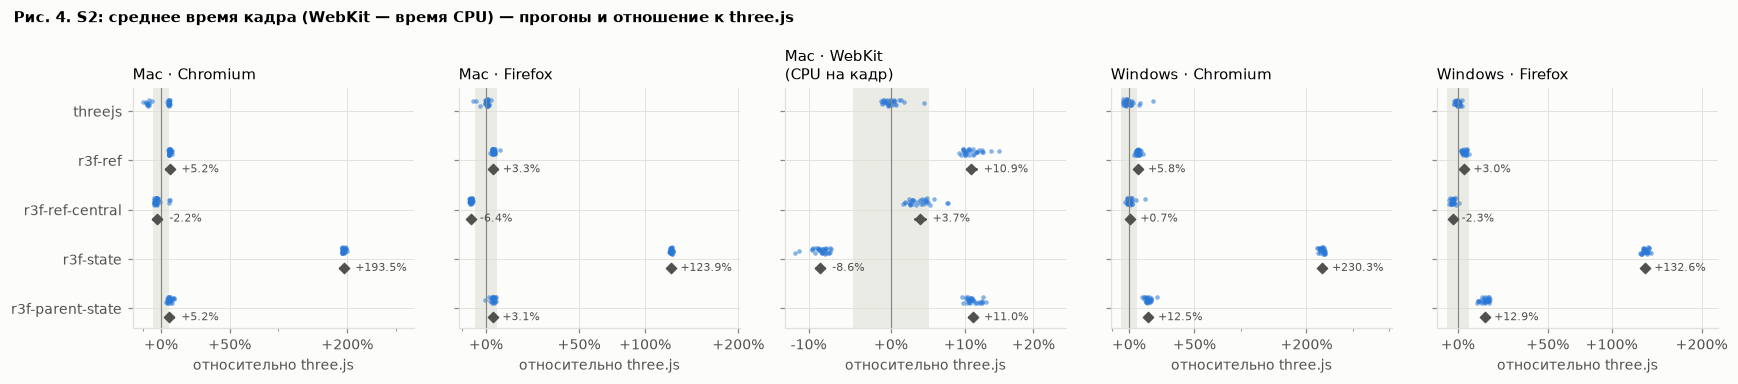

In [16]:
show_comparisons("s2")
plot_runs_and_ratio("s2", "Рис. 4. S2: среднее время кадра (WebKit — время CPU) — прогоны и отношение к three.js")

In [17]:
show_comparisons("s2", "дополнительная")

,платформа,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,r3f-ref,"кадр, медиана",+4.5%,[+2.4%; +6.9%],[+2.7%; +6.5%],±5%,0.0008,больше на 4.5%,хуже
1,Mac · Chromium,r3f-ref,"кадр, p99",+4.1%,[+2.0%; +6.6%],[+2.3%; +6.1%],±10%,0.0008,"≈ равны, разница +4.1%",
2,Mac · Chromium,r3f-ref-central,"кадр, медиана",-2.5%,[-4.7%; -0.0%],[-4.4%; -0.5%],±5%,0.0482,"≈ равны, разница -2.5%",
3,Mac · Chromium,r3f-ref-central,"кадр, p99",-2.8%,[-5.0%; -0.4%],[-4.7%; -0.8%],±10%,0.0272,"≈ равны, разница -2.8%",
4,Mac · Chromium,r3f-state,"кадр, медиана",+183.2%,[+177.2%; +189.6%],[+178.1%; +188.5%],±5%,0.0008,больше на 183.2%,хуже
5,Mac · Chromium,r3f-state,"кадр, p99",+271.7%,[+262.9%; +281.0%],[+264.4%; +279.3%],±10%,0.0008,больше на 271.7%,хуже
6,Mac · Chromium,r3f-parent-state,"кадр, медиана",+2.8%,[+0.6%; +5.1%],[+0.9%; +4.7%],±5%,0.0452,"≈ равны, разница +2.8%",
7,Mac · Chromium,r3f-parent-state,"кадр, p99",+59.5%,[+55.5%; +63.7%],[+56.1%; +63.0%],±10%,0.0008,больше на 59.5%,хуже
8,Mac · Firefox,r3f-ref,"кадр, медиана",+3.5%,[+2.8%; +4.2%],[+2.9%; +4.1%],±5%,0.0008,"≈ равны, разница +3.5%",
9,Mac · Firefox,r3f-ref,"кадр, p99",+2.2%,[+1.9%; +2.6%],[+1.9%; +2.6%],±10%,0.0008,"≈ равны, разница +2.2%",


**Фазы S2.** Здесь кадр ограничен процессором, поэтому разница вариантов
должна проявиться в логике (код анимации и React), отрисовке на CPU или
работе «вне фаз» (React-коммиты и сборка мусора между кадрами). В WebKit
«вне фаз» включает ожидание экрана.

,платформа,строка,"кадр, среднее",логика,отрисовка CPU,вне фаз,GPU,"Δ кадр, среднее",Δ логика,Δ отрисовка CPU,Δ вне фаз,Δ GPU,"Δ кадр, среднее, % от three.js"
0,Mac · Chromium,threejs,4.85,0.43,4.30,0.10,1.78,0.00,0.00,0.00,0.00,0.00,0.00
1,Mac · Chromium,r3f-ref,4.88,0.72,4.08,0.08,1.80,0.03,0.29,-0.22,-0.02,0.02,0.66
2,Mac · Chromium,r3f-ref-central,4.51,0.42,4.01,0.08,1.83,-0.34,-0.01,-0.29,-0.02,0.05,-6.97
3,Mac · Chromium,r3f-state,13.59,0.81,4.04,8.73,0.94,8.75,0.38,-0.27,8.63,-0.84,180.54
4,Mac · Chromium,r3f-parent-state,4.87,0.59,4.10,0.17,1.79,0.03,0.16,-0.21,0.07,0.01,0.55
5,Mac · Firefox,threejs,6.41,0.58,5.76,0.06,NaN,0.00,0.00,0.00,0.00,NaN,0.00
6,Mac · Firefox,r3f-ref,6.60,0.88,5.66,0.06,NaN,0.20,0.30,-0.11,0.01,NaN,3.07
7,Mac · Firefox,r3f-ref-central,5.97,0.58,5.33,0.06,NaN,-0.44,-0.01,-0.44,0.01,NaN,-6.85
8,Mac · Firefox,r3f-state,14.29,0.73,5.37,8.24,NaN,7.88,0.14,-0.39,8.18,NaN,123.02
9,Mac · Firefox,r3f-parent-state,6.59,0.78,5.55,0.26,NaN,0.18,0.20,-0.22,0.20,NaN,2.85


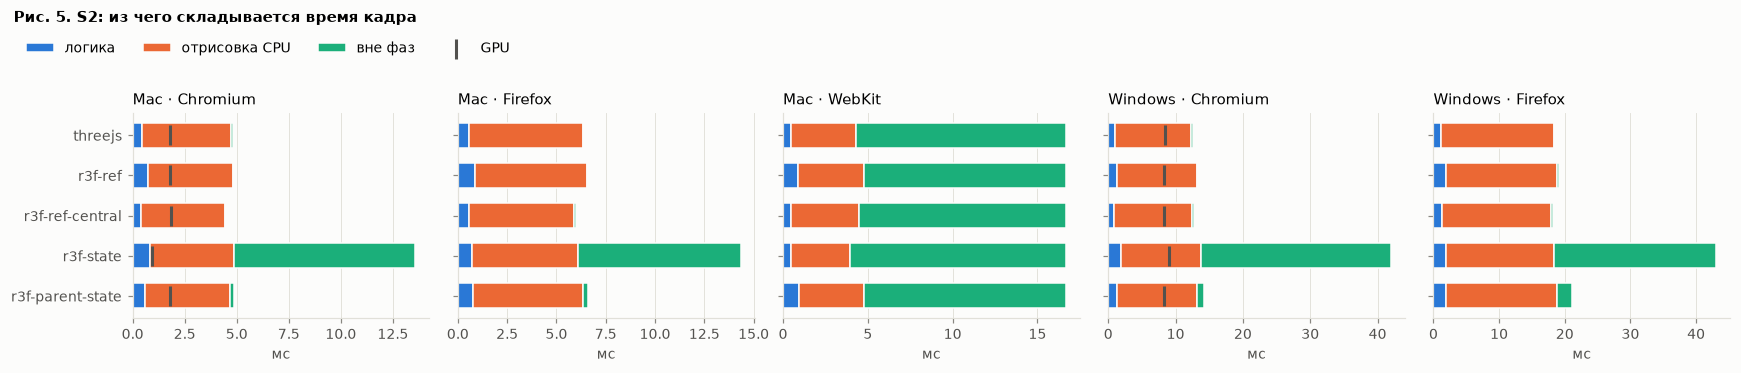

In [18]:
s2_phases = phase_table("s2", "кадр, среднее", S12_PARTS + ["GPU"])
show_phase_table(s2_phases, "кадр, среднее", S12_PARTS + ["GPU"])
plot_stacked(s2_phases, S12_PARTS, "Рис. 5. S2: из чего складывается время кадра", "мс", marker="GPU")

### 4.3. S3 — холодный старт и размер сборки

Страница открывается «с нуля» (новый процесс браузера, без кэша), и
измеряется **время до первого кадра** с полной сценой (100 статичных
объектов). Сцена неподвижна, поэтому у R3F один вариант — `r3f`. Время
раскладывается на этапы: загрузка и исполнение кода → построение сцены
(создание WebGL, объектов, ожидание первого кадра) → первая отрисовка.

Размер сборки — свойство сборки, а не прогона: он одинаков при каждом
открытии, поэтому приводится как есть, без статистики. Сборка делается на
каждой машине заново и одна на все браузеры этой машины, поэтому таблица —
по устройствам. На Mac и Windows размер может отличаться на десятые доли
КБ — на сравнение это не влияет.

In [19]:
bundles = []
for _, s in SERIES[SERIES["сценарий"] == "s3"].iterrows():
    for variant, size in s["manifest"]["bundles"].items():
        device = s["платформа"].split(" · ")[0]   # «Mac · Firefox» → «Mac»: сборка своя у машины, не у браузера
        bundles.append({"устройство": device, "вариант": variant, "КБ": size["raw_kb"], "КБ gzip": size["gzip_kb"]})
bundles = pd.DataFrame(bundles)
# Серии всех браузеров одной машины должны нести один и тот же размер — проверяем и оставляем по строке
sizes = bundles.drop_duplicates()
assert not sizes.duplicated(["устройство", "вариант"]).any(), "размер сборки различается между браузерами одной машины"
sizes = sizes.sort_values(["устройство", "вариант"], key=lambda c: c.map(VARIANTS.index) if c.name == "вариант" else c)
gzip_ref = sizes[sizes["вариант"] == REFERENCE].set_index("устройство")["КБ gzip"]
sizes["gzip, во сколько раз больше three.js"] = sizes["КБ gzip"] / sizes["устройство"].map(gzip_ref)
display(sizes.reset_index(drop=True).round(2))

,устройство,вариант,КБ,КБ gzip,"gzip, во сколько раз больше three.js"
0,Mac,threejs,549.1,138.0,1.00
1,Mac,r3f,1093.8,296.8,2.15
2,Windows,threejs,549.2,138.0,1.00
3,Windows,r3f,1093.9,296.8,2.15


,платформа,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,r3f,время до первого кадра,+124.2%,[+120.5%; +127.9%],[+121.1%; +127.3%],±5%,0.0002,больше на 124.2%,хуже
1,Mac · Firefox,r3f,время до первого кадра,+55.6%,[+54.0%; +57.3%],[+54.3%; +57.0%],±5%,0.0002,больше на 55.6%,хуже
2,Mac · WebKit,r3f,время до первого кадра,+47.9%,[+46.8%; +49.1%],[+46.9%; +48.9%],±5%,0.0002,больше на 47.9%,хуже
3,Windows · Chromium,r3f,время до первого кадра,+64.1%,[+62.1%; +67.0%],[+62.3%; +66.4%],±5%,0.0002,больше на 64.1%,хуже
4,Windows · Firefox,r3f,время до первого кадра,+34.0%,[+31.7%; +36.3%],[+32.0%; +35.9%],±5%,0.0002,больше на 34.0%,хуже


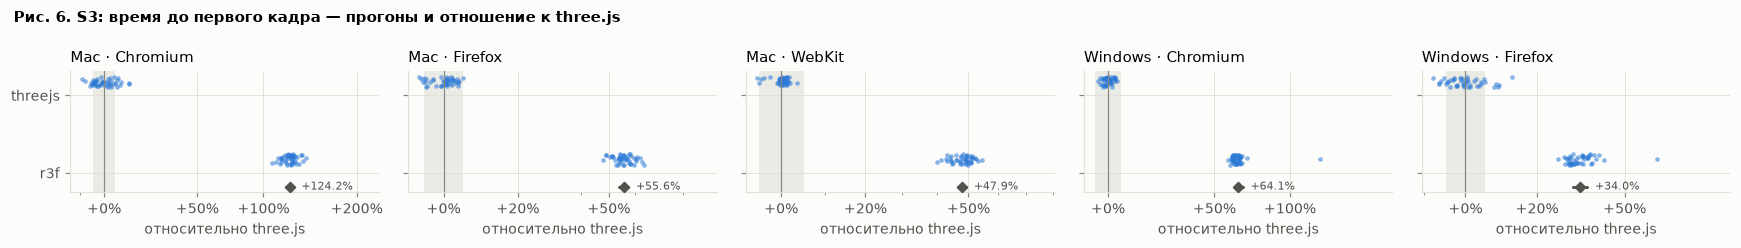

In [20]:
show_comparisons("s3")
plot_runs_and_ratio("s3", "Рис. 6. S3: время до первого кадра — прогоны и отношение к three.js")

,платформа,строка,время до первого кадра,загрузка кода,построение сцены,первая отрисовка,Δ время до первого кадра,Δ загрузка кода,Δ построение сцены,Δ первая отрисовка,"Δ время до первого кадра, % от three.js"
0,Mac · Chromium,threejs,103.04,42.40,38.77,20.40,0.00,0.00,0.00,0.00,0.00
1,Mac · Chromium,r3f,232.86,89.14,122.41,21.25,129.82,46.73,83.64,0.84,125.98
2,Mac · Firefox,threejs,178.04,125.96,31.06,21.28,0.00,0.00,0.00,0.00,0.00
3,Mac · Firefox,r3f,274.96,160.96,98.60,19.40,96.92,35.00,67.54,-1.88,54.44
4,Mac · WebKit,threejs,194.22,163.50,14.00,16.86,0.00,0.00,0.00,0.00,0.00
5,Mac · WebKit,r3f,288.48,180.86,91.56,17.66,94.26,17.36,77.56,0.80,48.53
6,Windows · Chromium,threejs,263.20,92.96,109.18,61.66,0.00,0.00,0.00,0.00,0.00
7,Windows · Chromium,r3f,428.79,174.53,201.05,53.23,165.60,81.58,91.87,-8.43,62.92
8,Windows · Firefox,threejs,492.48,266.34,89.34,133.04,0.00,0.00,0.00,0.00,0.00
9,Windows · Firefox,r3f,656.14,361.10,168.72,126.24,163.66,94.76,79.38,-6.80,33.23


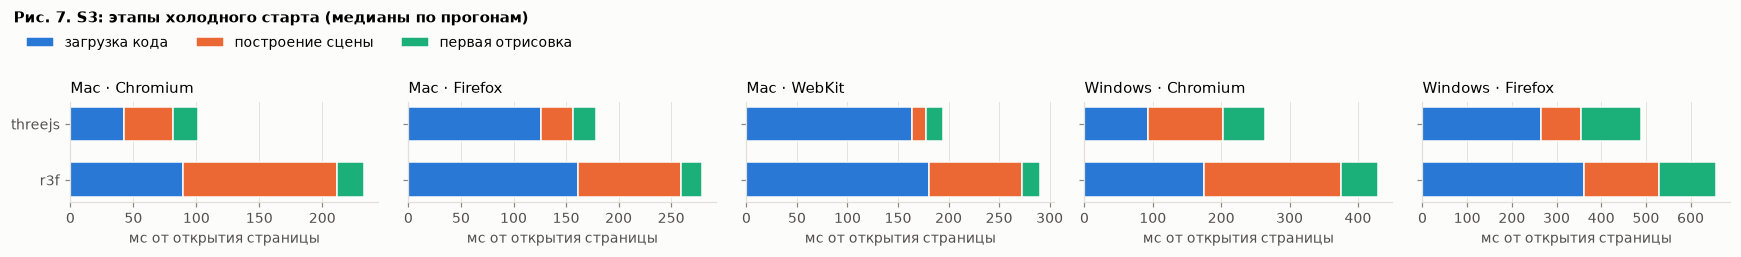

In [21]:
S3_PARTS = ["загрузка кода", "построение сцены", "первая отрисовка"]
s3_phases = phase_table("s3", "время до первого кадра", S3_PARTS)
show_phase_table(s3_phases, "время до первого кадра", S3_PARTS)
plot_stacked(s3_phases, S3_PARTS, "Рис. 7. S3: этапы холодного старта (медианы по прогонам)", "мс от открытия страницы")

### 4.4. S4 — отклик на клик

На сцене 2000 кубов; стенд кликает по ним настоящим вводом (через
Playwright) в случайные моменты времени, а отклик — подсветка куба —
фиксируется по фактическому цвету материала в отрисованном кадре.
Варианты: `threejs`, `r3f-ref` (ручная обработка клика, как в three.js) и
`r3f-events` (встроенная система событий R3F + `memo` + стор с селектором).

Задержка складывается из пяти фаз: **очередь** (событие ждёт, пока страница
его возьмёт) → **обработка** события → **обновление React** (если цвет
меняется не прямо в обработчике) → **ожидание кадра** → **отрисовка**.

Клики-промахи (не попали в объект) в задержку не входят; их доля — в
разделе 8.

,платформа,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,r3f-ref,"задержка, медиана",+1.5%,[-0.8%; +3.9%],[-0.5%; +3.5%],±10%,0.2526,≈ равны,
1,Mac · Chromium,r3f-events,"задержка, медиана",+13.4%,[+10.1%; +16.6%],[+10.7%; +16.1%],±10%,0.0004,больше на 13.4%,хуже
2,Mac · Firefox,r3f-ref,"задержка, медиана",+0.2%,[-2.7%; +3.1%],[-2.2%; +2.6%],±10%,0.9019,≈ равны,
3,Mac · Firefox,r3f-events,"задержка, медиана",+14.8%,[+11.5%; +18.3%],[+12.0%; +17.8%],±10%,0.0004,больше на 14.8%,хуже
4,Mac · WebKit,r3f-ref,"задержка, медиана",-0.5%,[-5.1%; +4.5%],[-4.4%; +3.6%],±10%,1.0000,≈ равны,
5,Mac · WebKit,r3f-events,"задержка, медиана",-0.9%,[-5.3%; +3.5%],[-4.6%; +2.9%],±10%,1.0000,≈ равны,
6,Windows · Chromium,r3f-ref,"задержка, медиана",+1.5%,[+0.3%; +2.8%],[+0.5%; +2.6%],±10%,0.0234,"≈ равны, разница +1.5%",
7,Windows · Chromium,r3f-events,"задержка, медиана",+6.7%,[+5.8%; +7.6%],[+5.9%; +7.5%],±10%,0.0004,"≈ равны, разница +6.7%",
8,Windows · Firefox,r3f-ref,"задержка, медиана",+4.6%,[+2.1%; +7.1%],[+2.5%; +6.7%],±10%,0.0016,"≈ равны, разница +4.6%",
9,Windows · Firefox,r3f-events,"задержка, медиана",+13.3%,[+10.4%; +16.0%],[+10.9%; +15.6%],±10%,0.0004,больше на 13.3%,хуже


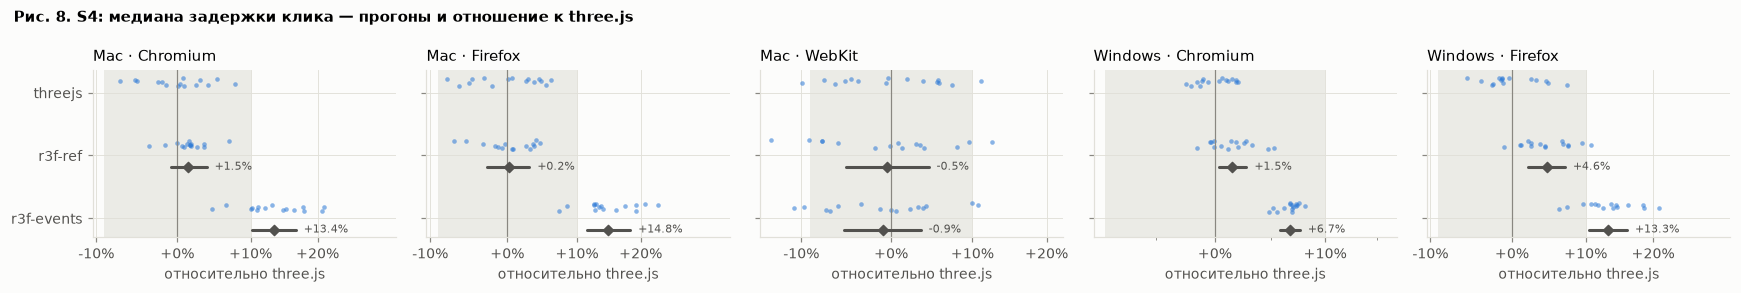

In [22]:
show_comparisons("s4")
plot_runs_and_ratio("s4", "Рис. 8. S4: медиана задержки клика — прогоны и отношение к three.js")

In [23]:
show_comparisons("s4", "дополнительная")

,платформа,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,r3f-ref,"задержка, p95",+0.7%,[-1.2%; +2.7%],[-0.9%; +2.3%],±10%,0.4780,≈ равны,
1,Mac · Chromium,r3f-events,"задержка, p95",+9.7%,[+7.7%; +11.6%],[+8.1%; +11.3%],±10%,0.0004,больше на 9.7%,хуже
2,Mac · Firefox,r3f-ref,"задержка, p95",+1.5%,[+0.4%; +2.5%],[+0.6%; +2.4%],±10%,0.0102,"≈ равны, разница +1.5%",
3,Mac · Firefox,r3f-events,"задержка, p95",+11.4%,[+10.2%; +12.6%],[+10.4%; +12.4%],±10%,0.0004,больше на 11.4%,хуже
4,Mac · WebKit,r3f-ref,"задержка, p95",-0.9%,[-3.2%; +1.4%],[-2.8%; +1.0%],±10%,0.4974,≈ равны,
5,Mac · WebKit,r3f-events,"задержка, p95",-1.7%,[-3.6%; +0.3%],[-3.3%; -0.1%],±10%,0.2232,≈ равны,
6,Windows · Chromium,r3f-ref,"задержка, p95",+1.9%,[-0.0%; +4.0%],[+0.3%; +3.7%],±10%,0.0850,≈ равны,
7,Windows · Chromium,r3f-events,"задержка, p95",+7.7%,[+5.3%; +10.1%],[+5.7%; +9.7%],±10%,0.0004,"≈ равны, разница +7.7%",
8,Windows · Firefox,r3f-ref,"задержка, p95",+3.0%,[-0.2%; +6.0%],[+0.4%; +5.6%],±10%,0.0674,≈ равны,
9,Windows · Firefox,r3f-events,"задержка, p95",+11.2%,[+7.7%; +14.5%],[+8.3%; +13.9%],±10%,0.0004,больше на 11.2%,хуже


**Фазы S4.** Медиана каждой фазы по кликам прогона, затем медиана по
прогонам. Медианы не складываются точно (медиана суммы ≠ сумме медиан),
поэтому столбец может немного отличаться от медианы задержки в таблице.
В Chromium и Firefox частота кадров не ограничена, и кадр начинается почти
сразу после обработки — ожидание кадра мало. В WebKit кадр ждёт экрана
(60 FPS), поэтому там заметная часть задержки — ожидание кадра, и оно
«поглощает» разницу в обработке события между вариантами.

,платформа,строка,"задержка, медиана",очередь,обработка,обновление React,ожидание кадра,отрисовка,"Δ задержка, медиана",Δ очередь,Δ обработка,Δ обновление React,Δ ожидание кадра,Δ отрисовка,"Δ задержка, медиана, % от three.js"
0,Mac · Chromium,threejs,6.56,2.22,0.30,0.0,0.05,3.93,0.00,0.00,0.00,0.0,0.00,0.00,0.00
1,Mac · Chromium,r3f-ref,6.64,2.28,0.31,0.0,0.06,3.99,0.08,0.06,0.01,0.0,0.01,0.05,1.26
2,Mac · Chromium,r3f-events,7.39,2.38,0.99,0.0,0.06,3.98,0.83,0.16,0.69,0.0,0.02,0.05,12.66
3,Mac · Firefox,threejs,8.22,2.96,0.48,0.0,0.10,4.72,0.00,0.00,0.00,0.0,0.00,0.00,0.00
4,Mac · Firefox,r3f-ref,8.22,2.80,0.58,0.0,0.12,4.72,-0.00,-0.16,0.10,0.0,0.02,0.00,-0.00
5,Mac · Firefox,r3f-events,9.29,2.68,1.84,0.0,0.12,4.70,1.07,-0.28,1.36,0.0,0.02,-0.02,13.02
6,Mac · WebKit,threejs,12.59,0.52,0.36,0.0,7.34,4.45,0.00,0.00,0.00,0.0,0.00,0.00,0.00
7,Mac · WebKit,r3f-ref,12.74,0.70,0.38,0.0,7.22,4.56,0.15,0.18,0.02,0.0,-0.12,0.11,1.19
8,Mac · WebKit,r3f-events,12.64,0.58,1.57,0.0,6.12,4.65,0.05,0.06,1.21,0.0,-1.22,0.20,0.40
9,Windows · Chromium,threejs,21.87,10.21,0.55,0.0,0.18,10.88,0.00,0.00,0.00,0.0,0.00,0.00,0.00


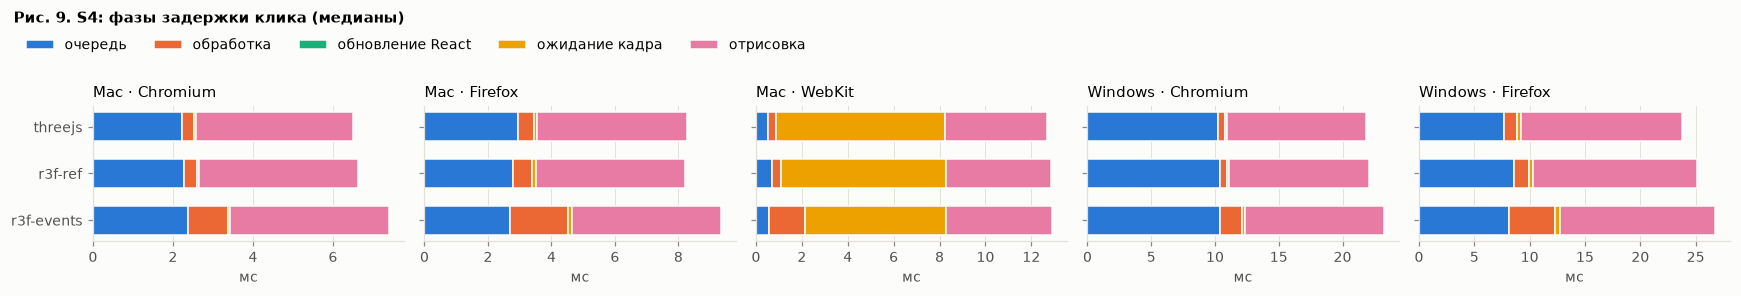

In [24]:
S4_PARTS = ["очередь", "обработка", "обновление React", "ожидание кадра", "отрисовка"]
s4_phases = phase_table("s4", "задержка, медиана", S4_PARTS)
show_phase_table(s4_phases, "задержка, медиана", S4_PARTS)
plot_stacked(s4_phases, S4_PARTS, "Рис. 9. S4: фазы задержки клика (медианы)", "мс")

### 4.5. S5 — масштабируемость

Число объектов растёт ступенями 100, 141, 200, … (×√2), пока FPS не упадёт
ниже 30. Рисунок 10 показывает сами кривые: по горизонтали — число
объектов, по вертикали — FPS (обе оси логарифмические). Линия — медиана по
прогонам, полоса — средние 50% прогонов. **Ёмкость** — где кривая
пересекает пунктир 60 FPS (и 30 FPS). Чем правее пересечение, тем больше
объектов вариант выдерживает.

Если на какой-то ступени FPS не пересёк порог в пройденных пределах,
ёмкость прогона не определена; такие ячейки сравниваются по рангам, без R
(раздел 5 ANALYSIS.md, вопрос 4).

Прогонов с неопределённой ёмкостью: **0**.

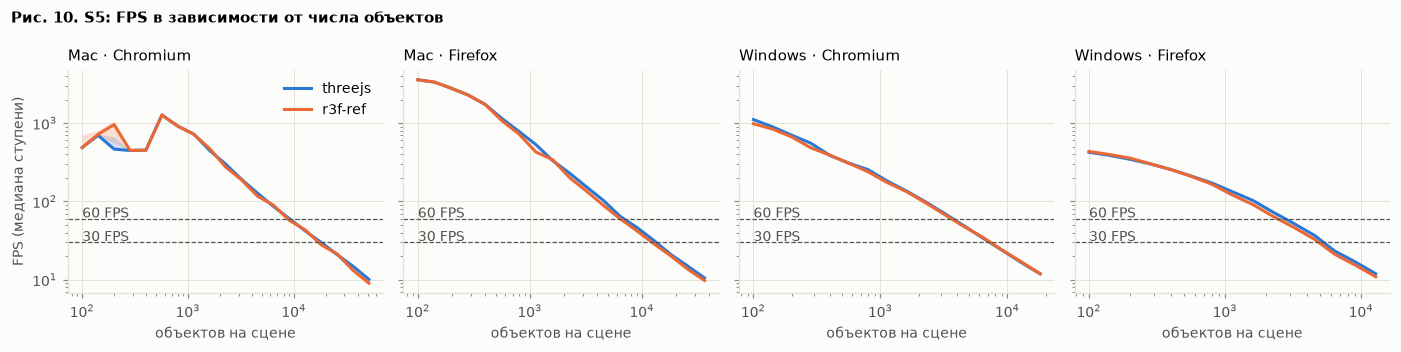

In [25]:
s5 = RUNS[RUNS["сценарий"] == "s5"]
undefined = s5[~np.isfinite(s5["ёмкость при 30 FPS"]) | (s5[MAIN["s5"]] == 0).any(axis=1)
               | ~np.isfinite(s5["ёмкость при 60 FPS"])]
display(Markdown(f"Прогонов с неопределённой ёмкостью: **{len(undefined)}**."))

platforms = [p for p in PLATFORMS if p in set(LEVELS["платформа"])]
fig, axes = plt.subplots(1, len(platforms), figsize=(3.2 * len(platforms), 3.2), sharey=True, squeeze=False)
for ax, platform in zip(axes[0], platforms):
    for color, variant in zip(SERIES_COLORS, ["threejs", "r3f-ref"]):
        d = LEVELS[(LEVELS["платформа"] == platform) & (LEVELS["вариант"] == variant)]
        q = d.groupby("объектов")["FPS"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.fill_between(q.index, q[0.25], q[0.75], color=color, alpha=0.2, lw=0)
        ax.plot(q.index, q[0.5], color=color, lw=2, label=variant)
    for fps in (60, 30):
        ax.axhline(fps, color=INK, lw=0.8, ls="--")
        ax.text(LEVELS["объектов"].min(), fps * 1.04, f"{fps} FPS", color=INK)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(platform)
    ax.set_xlabel("объектов на сцене")
axes[0][0].set_ylabel("FPS (медиана ступени)")
axes[0][0].legend(loc="upper right")
figure_title(fig, "Рис. 10. S5: FPS в зависимости от числа объектов")
fig.tight_layout()
plt.show()

,платформа,вариант,метрика,R − 1,95% интервал,90% интервал,порог δ,p (Холм),вывод,для R3F
0,Mac · Chromium,r3f-ref,ёмкость при 60 FPS,-2.5%,[-3.8%; -1.2%],[-3.6%; -1.4%],±5%,0.0008,"≈ равны, разница -2.5%",
1,Mac · Chromium,r3f-ref,ёмкость при 30 FPS,-3.1%,[-4.8%; -1.3%],[-4.6%; -1.6%],±5%,0.0010,"≈ равны, разница -3.1%",
2,Mac · Firefox,r3f-ref,ёмкость при 60 FPS,-8.7%,[-9.8%; -7.5%],[-9.7%; -7.7%],±5%,0.0004,меньше на 8.7%,хуже
3,Mac · Firefox,r3f-ref,ёмкость при 30 FPS,-8.0%,[-9.2%; -6.9%],[-9.0%; -7.1%],±5%,0.0004,меньше на 8.0%,хуже
4,Windows · Chromium,r3f-ref,ёмкость при 60 FPS,-3.3%,[-4.9%; -1.9%],[-4.6%; -2.1%],±5%,0.0004,"≈ равны, разница -3.3%",
5,Windows · Chromium,r3f-ref,ёмкость при 30 FPS,+0.8%,[-0.9%; +2.4%],[-0.6%; +2.1%],±5%,0.3454,≈ равны,
6,Windows · Firefox,r3f-ref,ёмкость при 60 FPS,-12.2%,[-12.9%; -11.6%],[-12.8%; -11.7%],±5%,0.0004,меньше на 12.2%,хуже
7,Windows · Firefox,r3f-ref,ёмкость при 30 FPS,-8.1%,[-8.5%; -7.7%],[-8.5%; -7.8%],±5%,0.0004,меньше на 8.1%,хуже


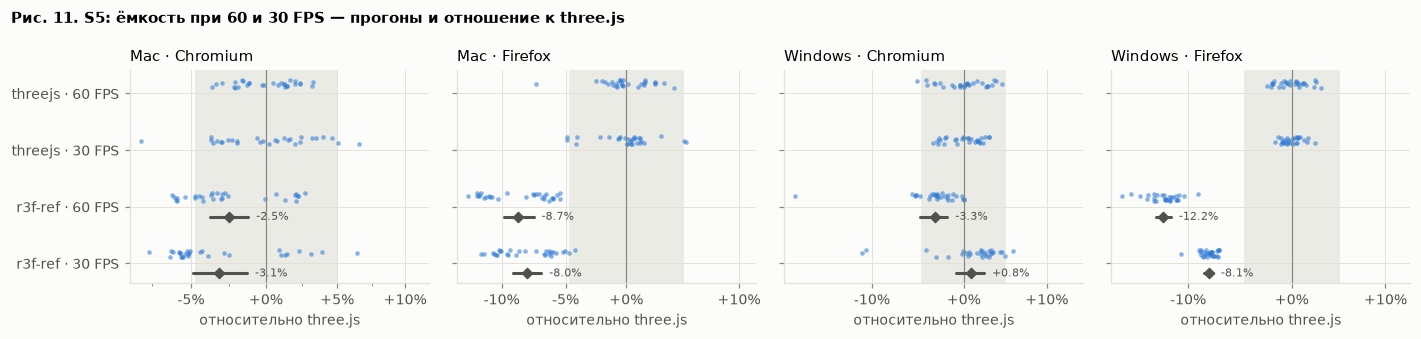

In [26]:
show_comparisons("s5")
plot_runs_and_ratio("s5", "Рис. 11. S5: ёмкость при 60 и 30 FPS — прогоны и отношение к three.js")

## 5. Двухуровневые ячейки

Иногда прогоны одной ячейки делятся на **две устойчивые группы**: часть
прогонов стабильно быстрее, часть — медленнее, а между ними пусто. В пилоте
так вёл себя three.js в S2 на Mac · Chromium: уровень выбирался при старте
процесса браузера (по-видимому, случайное состояние движка JavaScript V8) и
держался весь прогон. Это свойство процесса браузера, а не технологии, и
одно число (R) такую ячейку описывает плохо. Поэтому такие ячейки
описываются отдельно (правило 4.6): где каждый уровень и какая доля прогонов
на него попадает.

**Критерий** (тот же, что в пилоте). Значения ячейки упорядочиваются и
делятся по наибольшему разрыву. Ячейка двухуровневая, если одновременно:

- в каждой группе не меньше 3 прогонов (при 30 и более прогонах; иначе — 2);
- разрыв больше 4 стандартных отклонений внутри групп — группы чётко
  отделены;
- разрыв не меньше порога δ — иначе это мелкая «ступенька».

Для доли прогонов на нижнем уровне приводится 95%-ный интервал Уилсона
(`statsmodels.proportion_confint`) — стандартный интервал для доли.

In [27]:
def split_levels(values, delta):
    # Граница между двумя уровнями или None, если ячейка одноуровневая
    x = np.sort(np.log(np.asarray(values, float)))
    if len(x) < 4 or not np.isfinite(x).all():
        return None
    min_group = 3 if len(x) >= 30 else 2
    i = int(np.argmax(np.diff(x)))
    low, high = x[: i + 1], x[i + 1:]
    if len(low) < min_group or len(high) < min_group:
        return None
    within = max(np.std(low, ddof=1), np.std(high, ddof=1), 1e-4)
    gap = high[0] - low[-1]
    if gap > 4 * within and gap >= math.log1p(delta):
        return math.exp((low[-1] + high[0]) / 2)
    return None


rows = []
for (platform, scenario, point, variant), cell in RUNS.groupby(["платформа", "сценарий", "точка", "вариант"]):
    for metric in metrics_for(platform, scenario)[0]:
        values = cell[metric]
        border = split_levels(values, DELTA[metric])
        if border is None:
            continue
        low, high = values[values < border], values[values >= border]
        share_lo, share_hi = proportion_confint(len(low), len(values), alpha=0.05, method="wilson")
        rows.append({"платформа": platform, "сценарий": scenario, "точка": point, "вариант": variant,
                     "метрика": metric, "n": len(values),
                     "нижний уровень": geomean(low), "верхний уровень": geomean(high),
                     "разрыв": pct(geomean(high) / geomean(low)),
                     "доля на нижнем": len(low) / len(values),
                     "95% интервал доли": f"[{share_lo:.0%}; {share_hi:.0%}]",
                     "граница": border})
TWO_LEVELS = pd.DataFrame(rows)
if TWO_LEVELS.empty:
    display(Markdown("Двухуровневых ячеек нет."))
else:
    TWO_LEVELS = in_order(TWO_LEVELS)
    display(TWO_LEVELS.drop(columns="граница").round(3).style.format({"доля на нижнем": "{:.0%}"}, precision=3))

,платформа,сценарий,точка,вариант,метрика,n,нижний уровень,верхний уровень,разрыв,доля на нижнем,95% интервал доли
0,Mac · Chromium,s2,-,threejs,"кадр, среднее",30,4.284,4.857,+13.4%,37%,[22%; 54%]
1,Mac · Chromium,s2,-,r3f-ref-central,"кадр, среднее",30,4.500,4.882,+8.5%,90%,[74%; 97%]


На рисунке — значения каждой двухуровневой ячейки в порядке съёмки (номер
прогона в серии). Если уровни — состояние процесса, а не дрейф условий,
верхние и нижние прогоны перемешаны по всей серии, а не идут блоками
«сначала одни, потом другие».

Сравнение такой ячейки с three.js остаётся в таблицах раздела 4 (общее R по
всем прогонам), но читать его нужно с этой оговоркой: интервал широкий, и
вывод часто «не ясно» — это честное отражение того, что разброс задаётся
состоянием браузера, а не технологией.

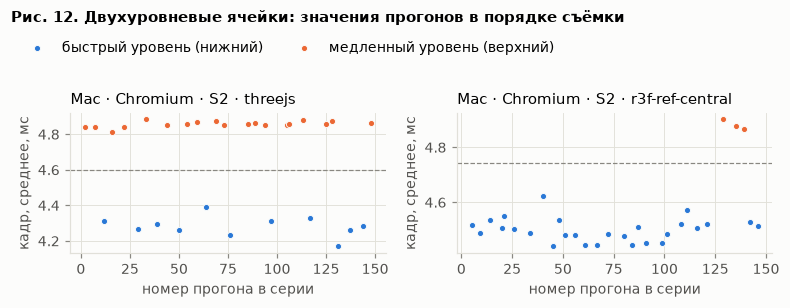

In [28]:
if not TWO_LEVELS.empty:
    fig, axes = plt.subplots(1, len(TWO_LEVELS), figsize=(3.6 * len(TWO_LEVELS), 2.8), squeeze=False)
    for ax, (_, t) in zip(axes[0], TWO_LEVELS.iterrows()):
        cell = RUNS[(RUNS["платформа"] == t["платформа"]) & (RUNS["сценарий"] == t["сценарий"])
                    & (RUNS["точка"] == t["точка"]) & (RUNS["вариант"] == t["вариант"])]
        is_low = cell[t["метрика"]] < t["граница"]
        for color, mask, name in [(SERIES_COLORS[0], is_low, "быстрый уровень (нижний)"),
                                 (SERIES_COLORS[1], ~is_low, "медленный уровень (верхний)")]:
            ax.scatter(cell.loc[mask, "номер"], cell.loc[mask, t["метрика"]], s=16, color=color, label=name,
                       edgecolor=SURFACE, linewidth=0.6)
        ax.axhline(t["граница"], color=MUTED, lw=0.8, ls="--")
        ax.set_title(f"{t['платформа']} · {t['сценарий'].upper()} · {t['вариант']}"
                     + ("" if t["точка"] == "-" else f" · {t['точка']}"))
        ax.set_xlabel("номер прогона в серии")
        ax.set_ylabel(t["метрика"] + ", мс" if "ёмкость" not in t["метрика"] else t["метрика"])
    # Легенда над панелями, вне области данных — чтобы её значки не путались с прогонами
    handles, names = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, names, loc="upper left", bbox_to_anchor=(0.01, 0.92), ncol=2)
    figure_title(fig, "Рис. 12. Двухуровневые ячейки: значения прогонов в порядке съёмки")
    fig.tight_layout(rect=(0, 0, 1, 0.86))
    plt.show()

**Примечание к рис. 12.** `r3f-ref-central` мы не считаем двухуровневой
ячейкой: формальный разрыв образован тремя верхними прогонами, которые
идут подряд, тогда как остальные прогоны находятся на нижнем уровне.
Такой блочный рисунок не подтверждает переключение между устойчивыми
состояниями процесса и скорее указывает на кратковременный режим или
группу выбросов. Прогоны не удаляются, но ячейка не интерпретируется
как двухуровневая.


## 6. Сравнение платформ

Одно и то же сравнение (например, «S2 · r3f-state против three.js») на разных
платформах может давать разный результат: другой движок JavaScript, другая
видеокарта. Здесь отношения R главных метрик всех платформ сведены в одну
картину (правило 4.9). Это **описательное** сравнение: абсолютные
миллисекунды разных машин не сравниваются, и отдельных тестов «платформа
против платформы» нет.

**Как читать рисунок.** Строка — сравнение, столбец — платформа. В клетке —
R − 1 в процентах и знак вывода: **≈** — практически равны, **?** — не ясно,
без знака — существенная разница. Цвет показывает, *хуже или лучше для R3F*:
красный — R3F хуже three.js (медленнее, или меньше ёмкость), синий — лучше,
серый — около нуля. Шкала цвета логарифмическая и ограничена ±100%, чтобы
очень большие эффекты не «съели» различия поменьше. Пустая клетка — сценарий
на этой платформе не снимался (WebKit: S1 и S5). В WebKit S2 сравнивается
время CPU на кадр.

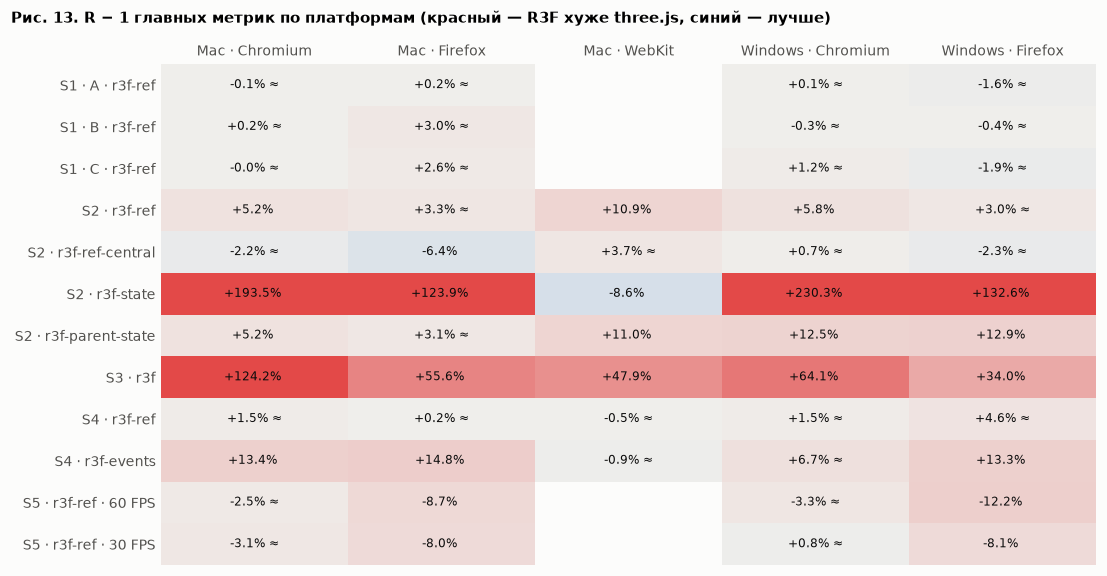

In [29]:
main = COMP[COMP["роль"] == "главная"].copy()
main["сравнение"] = [f"{s.upper()} · " + row_label(s, p, v, MAIN[s].index(m) if s == "s5" else 0)
                     for s, p, v, m in zip(main["сценарий"], main["точка"], main["вариант"], main["метрика"])]
# Знак эффекта «хуже для R3F»: для ёмкости больше — лучше, поэтому знак переворачивается
main["хуже для R3F"] = np.log(main["R"]) * np.where(main["метрика"].isin(HIGHER_IS_BETTER), -1, 1)
main["знак"] = main["вывод"].map(lambda v: "≈" if v.startswith("≈") else "?" if v == "не ясно" else "")

rows = list(dict.fromkeys(main["сравнение"]))
cols = [p for p in PLATFORMS if p in set(main["платформа"])]
effect = main.pivot(index="сравнение", columns="платформа", values="хуже для R3F").reindex(index=rows, columns=cols)
ratio = main.pivot(index="сравнение", columns="платформа", values="R").reindex(index=rows, columns=cols)
mark = main.pivot(index="сравнение", columns="платформа", values="знак").reindex(index=rows, columns=cols)

diverging = LinearSegmentedColormap.from_list("better-worse", ["#2a78d6", "#f0efec", "#e34948"])
limit = math.log(2)
fig, ax = plt.subplots(figsize=(1.5 * len(cols) + 2.6, 0.34 * len(rows) + 1.2))
ax.imshow(effect.clip(-limit, limit), cmap=diverging, vmin=-limit, vmax=limit, aspect="auto")
for i in range(len(rows)):
    for j in range(len(cols)):
        if pd.notna(ratio.iat[i, j]):
            ax.text(j, i, f"{pct(ratio.iat[i, j])} {mark.iat[i, j]}", ha="center", va="center", color="#0b0b0b", fontsize=8)
ax.set_xticks(range(len(cols)), cols)
ax.set_yticks(range(len(rows)), rows)
ax.xaxis.tick_top()
ax.grid(False)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
figure_title(fig, "Рис. 13. R − 1 главных метрик по платформам (красный — R3F хуже three.js, синий — лучше)")
fig.tight_layout()
plt.show()

Та же информация таблицей — выводы по главным метрикам:

In [30]:
display(main.pivot(index="сравнение", columns="платформа", values="вывод").reindex(index=rows, columns=cols).fillna("—"))

платформа,Mac · Chromium,Mac · Firefox,Mac · WebKit,Windows · Chromium,Windows · Firefox
сравнение,,,,,
S1 · A · r3f-ref,≈ равны,≈ равны,—,≈ равны,"≈ равны, разница -1.6%"
S1 · B · r3f-ref,"≈ равны, разница +0.2%","≈ равны, разница +3.0%",—,"≈ равны, разница -0.3%",≈ равны
S1 · C · r3f-ref,≈ равны,"≈ равны, разница +2.6%",—,"≈ равны, разница +1.2%",≈ равны
S2 · r3f-ref,больше на 5.2%,"≈ равны, разница +3.3%",больше на 10.9%,больше на 5.8%,"≈ равны, разница +3.0%"
S2 · r3f-ref-central,≈ равны,меньше на 6.4%,"≈ равны, разница +3.7%",≈ равны,"≈ равны, разница -2.3%"
S2 · r3f-state,больше на 193.5%,больше на 123.9%,меньше на 8.6%,больше на 230.3%,больше на 132.6%
S2 · r3f-parent-state,больше на 5.2%,"≈ равны, разница +3.1%",больше на 11.0%,больше на 12.5%,больше на 12.9%
S3 · r3f,больше на 124.2%,больше на 55.6%,больше на 47.9%,больше на 64.1%,больше на 34.0%
S4 · r3f-ref,≈ равны,≈ равны,≈ равны,"≈ равны, разница +1.5%","≈ равны, разница +4.6%"


## 7. WebKit: что сравнивается

В WebKit (Safari) нельзя снять ограничение частоты кадров: если кадр готов
быстрее 16,7 мс, он всё равно ждёт экрана. Поэтому:

- **S2** — главная метрика вместо времени кадра — **время работы CPU на
  кадр** (среднее логики + отрисовки). Время кадра приводится ниже, но не
  сравнивается: оно у всех ≈ 16,7 мс;
- **S3, S4** — как на других платформах. Задержка S4 включает ожидание
  экрана — это то, что видит пользователь Safari;
- **S1, S5** не снимались: без GPU-таймера и при ограничении 60 FPS нагрузку
  на видеокарту не видно, а на больших S5 WebKit теряет контекст WebGL.

Таблица — медианы по прогонам S2 в WebKit: время кадра действительно
упирается в экран, а время CPU различает варианты. Ограничение: работа
React вне фаз (`r3f-state`) в время CPU не попадает — см. оговорку в
разделе 4.2.

In [31]:
webkit = RUNS[(RUNS["платформа"] == "Mac · WebKit") & (RUNS["сценарий"] == "s2")]
if len(webkit):
    display(in_order(webkit.groupby("вариант")[["кадр, среднее", "CPU на кадр", "логика", "отрисовка CPU"]]
                     .median().reset_index()).round(3))

,вариант,"кадр, среднее",CPU на кадр,логика,отрисовка CPU
0,threejs,16.666,4.299,0.442,3.858
1,r3f-ref,16.666,4.760,0.873,3.886
2,r3f-ref-central,16.666,4.467,0.464,4.002
3,r3f-state,16.666,3.943,0.493,3.453
4,r3f-parent-state,16.666,4.770,0.941,3.833


## 8. Качество данных

Этот раздел не влияет на выводы — он показывает, можно ли данным доверять
(правило 4.10).

### 8.1. Сбои браузера

Если браузер падал, стенд повторял прогон; такие случаи записаны в
`retries` серии.

In [32]:
retries = [{"платформа": s["платформа"], "сценарий": s["сценарий"], **r}
           for _, s in SERIES.iterrows() for r in s["manifest"]["retries"]]
display(pd.DataFrame(retries) if retries else Markdown("Сбоев браузера не было ни в одной серии."))

Сбоев браузера не было ни в одной серии.

### 8.2. Дрейф условий

Кампания шла часами. Если за это время машина нагревалась или в фоне
что-то запускалось, метрика могла плавно «уплыть» от начала серии к концу.
Проверка: для каждой ячейки считается **ранговая корреляция Спирмена**
(`scipy.stats.spearmanr`) между номером прогона в серии и его метрикой.
ρ около 0 — дрейфа нет; ρ около +1 — к концу серии метрика стабильно растёт.

Даже без всякого дрейфа примерно 5% ячеек случайно покажут p < 0,05 — это
нормально. Тревожный признак — много ячеек с большим |ρ| в одной серии и с
одним знаком. Варианты в серии чередуются в случайном порядке, поэтому
даже настоящий дрейф затрагивает их одинаково и сравнение не искажает —
но увеличивает разброс.

In [33]:
rows = []
for (platform, scenario, point, variant), cell in RUNS.groupby(["платформа", "сценарий", "точка", "вариант"]):
    for metric in metrics_for(platform, scenario)[0]:
        rho, p = stats.spearmanr(cell["номер"], cell[metric])
        rows.append({"платформа": platform, "сценарий": scenario, "точка": point, "вариант": variant,
                     "метрика": metric, "n": len(cell), "ρ": rho, "p": p})
DRIFT = in_order(pd.DataFrame(rows))

display(Markdown(f"Ячеек: {len(DRIFT)}; с p < 0,05: **{(DRIFT['p'] < 0.05).sum()}** "
                 f"(случайно ожидается ≈ {0.05 * len(DRIFT):.0f})."))
display(DRIFT.groupby(["платформа", "сценарий"])["ρ"].agg(["min", "median", "max"]).unstack().round(2))
display(Markdown("Ячейки с наибольшим |ρ|:"))
display(DRIFT.reindex(DRIFT["ρ"].abs().sort_values(ascending=False).index).head(10).round(3))

Ячеек: 90; с p < 0,05: **7** (случайно ожидается ≈ 4).

min                         median                           max                        
сценарий              s1    s2    s3    s4    s5     s1    s2    s3    s4    s5    s1    s2    s3    s4    s5
платформа                                                                                                    
Mac · Chromium     -0.36 -0.26 -0.16 -0.44 -0.03   0.05  0.02 -0.14  0.02  0.07  0.32  0.24 -0.12  0.29  0.09
Mac · Firefox      -0.55 -0.22 -0.44 -0.14 -0.34   0.05  0.12 -0.43  0.24 -0.25  0.55  0.55 -0.41  0.36 -0.00
Mac · WebKit         NaN -0.10 -0.03 -0.64   NaN    NaN -0.01 -0.01 -0.56   NaN   NaN  0.20  0.01 -0.42   NaN
Windows · Chromium -0.48 -0.22  0.01 -0.07 -0.22   0.00  0.02  0.06  0.28  0.06  0.66  0.10  0.11  0.42  0.33
Windows · Firefox  -0.16 -0.29 -0.16  0.18 -0.03   0.05 -0.04 -0.13  0.36  0.17  0.65  0.07 -0.10  0.49  0.32

Ячейки с наибольшим |ρ|:

,платформа,сценарий,точка,вариант,метрика,n,ρ,p
54,Windows · Chromium,s1,C,threejs,"кадр, среднее",10,0.661,0.038
72,Windows · Firefox,s1,B,threejs,"кадр, среднее",10,0.648,0.043
48,Mac · WebKit,s4,-,r3f-ref,"задержка, медиана",15,-0.636,0.011
49,Mac · WebKit,s4,-,r3f-events,"задержка, медиана",15,-0.557,0.031
27,Mac · Firefox,s2,-,r3f-ref,"кадр, среднее",30,0.552,0.002
23,Mac · Firefox,s1,B,r3f-ref,"кадр, среднее",10,-0.552,0.098
20,Mac · Firefox,s1,A,threejs,"кадр, среднее",10,0.552,0.098
22,Mac · Firefox,s1,B,threejs,"кадр, среднее",10,0.527,0.117
83,Windows · Firefox,s4,-,threejs,"задержка, медиана",15,0.493,0.062
53,Windows · Chromium,s1,B,r3f-ref,"кадр, среднее",10,-0.479,0.162


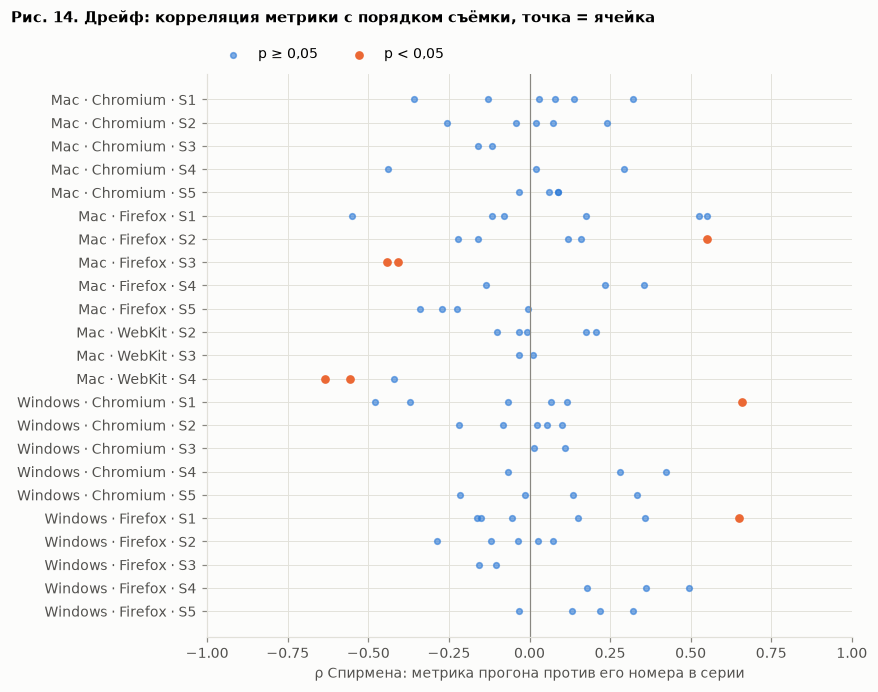

In [34]:
fig, ax = plt.subplots(figsize=(8, 2.6))
labels = [f"{p} · {s.upper()}" for p, s in zip(DRIFT["платформа"], DRIFT["сценарий"])]
order = list(dict.fromkeys(labels))
y = [order.index(label) for label in labels]
ax.axvline(0, color=MUTED, lw=0.8)
significant = DRIFT["p"] < 0.05
ax.scatter(DRIFT.loc[~significant, "ρ"], np.array(y)[~significant], s=14, color=SERIES_COLORS[0], alpha=0.6, label="p ≥ 0,05")
ax.scatter(DRIFT.loc[significant, "ρ"], np.array(y)[significant], s=22, color=SERIES_COLORS[1], label="p < 0,05")
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(-1, 1)
ax.set_xlabel("ρ Спирмена: метрика прогона против его номера в серии")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.set_size_inches(8, 0.22 * len(order) + 1.3)
figure_title(fig, "Рис. 14. Дрейф: корреляция метрики с порядком съёмки, точка = ячейка")
fig.tight_layout()
plt.show()

### 8.3. S4: исходы кликов

Клик может не попасть в объект (`miss`) — стенд кликает в случайную точку
экрана. Важно, чтобы доля промахов не зависела от варианта: иначе варианты
сравнивались бы на разных наборах кликов. Прочие исходы (`timeout` — отклика
нет за 2 с, `superseded` — следующий клик пришёл раньше отклика) говорили
бы о сбоях.

In [35]:
clicks = RUNS[RUNS["сценарий"] == "s4"]
display(in_order(clicks.groupby(["платформа", "вариант"])
                 .agg(прогонов=("кликов", "size"), кликов_на_прогон=("кликов", "median"),
                      доля_промахов=("доля промахов", "mean"), доля_прочих=("доля прочих исходов", "mean"))
                 .reset_index()).style.format({"доля_промахов": "{:.1%}", "доля_прочих": "{:.2%}"}))

,платформа,вариант,прогонов,кликов_на_прогон,доля_промахов,доля_прочих
0,Mac · Chromium,threejs,15,97.000000,22.1%,0.00%
1,Mac · Chromium,r3f-ref,15,97.000000,22.1%,0.00%
2,Mac · Chromium,r3f-events,15,97.000000,22.1%,0.00%
3,Mac · Firefox,threejs,15,90.000000,22.6%,0.00%
4,Mac · Firefox,r3f-ref,15,90.000000,22.6%,0.00%
5,Mac · Firefox,r3f-events,15,89.000000,22.5%,0.00%
6,Mac · WebKit,threejs,15,95.000000,22.0%,0.00%
7,Mac · WebKit,r3f-ref,15,94.000000,22.1%,0.00%
8,Mac · WebKit,r3f-events,15,94.000000,22.1%,0.00%
9,Windows · Chromium,threejs,15,89.000000,22.4%,0.00%


### 8.4. S1, S2: покрытие GPU-таймером

Время GPU замеряется асинхронно, и для части кадров замер может не успеть.
Доля кадров с измеренным GPU-временем (только Chromium; в Firefox и WebKit
таймера нет):

In [36]:
gpu = RUNS[RUNS["сценарий"].isin(["s1", "s2"]) & RUNS["платформа"].str.contains("Chromium")]
display(gpu.groupby(["платформа", "сценарий"])["доля кадров с GPU"].agg(["min", "mean"])
        .style.format("{:.2%}"))

### 8.5. Сводка

Двухуровневые ячейки разобраны в разделе 5. Сводка качества:

In [37]:
summary = {
    "серий допущено": f"{len(SERIES)} из {len(SERIES) + len(rejected)}",
    "прогонов": len(RUNS),
    "сбоев браузера": len(retries),
    "ячеек с дрейфом (p < 0,05)": f"{(DRIFT['p'] < 0.05).sum()} из {len(DRIFT)}",
    "двухуровневых ячеек": len(TWO_LEVELS),
    "прогонов S5 с неопределённой ёмкостью": len(undefined),
}
display(pd.Series(summary, name="значение").to_frame())

,значение
серий допущено,23 из 23
прогонов,1897
сбоев браузера,0
"ячеек с дрейфом (p < 0,05)",7 из 90
двухуровневых ячеек,2
прогонов S5 с неопределённой ёмкостью,0


## 9. Итог

Сводная таблица выводов по главным метрикам — раздел 6 (таблица после
рис. 13). Ниже — все существенные различия (вывод «больше/меньше»),
отсортированные по величине эффекта, и все случаи «не ясно».

In [38]:
cols = ["платформа", "сценарий", "точка", "вариант", "метрика", "R", "вывод", "для R3F"]
strong = main[main["вывод"].str.startswith(("больше", "меньше"))].copy()
strong["|эффект|"] = strong["хуже для R3F"].abs()
display(Markdown(f"**Существенные различия:** {len(strong)} из {len(main)} сравнений."))
display(strong.sort_values("|эффект|", ascending=False)[cols].assign(R=lambda d: d["R"].map(pct)).reset_index(drop=True))

unclear = main[main["вывод"] == "не ясно"]
display(Markdown(f"**Не ясно:** {len(unclear)}."))
if len(unclear):
    display(unclear[cols + ["95% от", "95% до"]].assign(R=lambda d: d["R"].map(pct)).round(3).reset_index(drop=True))

equal = main[main["вывод"].str.startswith("≈")]
display(Markdown(f"**Практически равны three.js:** {len(equal)}."))

**Существенные различия:** 25 из 55 сравнений.

,платформа,сценарий,точка,вариант,метрика,R,вывод,для R3F
0,Windows · Chromium,s2,-,r3f-state,"кадр, среднее",+230.3%,больше на 230.3%,хуже
1,Mac · Chromium,s2,-,r3f-state,"кадр, среднее",+193.5%,больше на 193.5%,хуже
2,Windows · Firefox,s2,-,r3f-state,"кадр, среднее",+132.6%,больше на 132.6%,хуже
3,Mac · Chromium,s3,-,r3f,время до первого кадра,+124.2%,больше на 124.2%,хуже
4,Mac · Firefox,s2,-,r3f-state,"кадр, среднее",+123.9%,больше на 123.9%,хуже
5,Windows · Chromium,s3,-,r3f,время до первого кадра,+64.1%,больше на 64.1%,хуже
6,Mac · Firefox,s3,-,r3f,время до первого кадра,+55.6%,больше на 55.6%,хуже
7,Mac · WebKit,s3,-,r3f,время до первого кадра,+47.9%,больше на 47.9%,хуже
8,Windows · Firefox,s3,-,r3f,время до первого кадра,+34.0%,больше на 34.0%,хуже
9,Mac · Firefox,s4,-,r3f-events,"задержка, медиана",+14.8%,больше на 14.8%,хуже


**Не ясно:** 0.

**Практически равны three.js:** 30.

### Главное

> Результаты запуска на данных кампании r3

1. **Нагрузка на видеокарту (S1): R3F ничего не стоит.** На всех платформах и
   во всех точках нагрузки `r3f-ref` практически равен three.js: кадр
   ограничен видеокартой, и работа R3F на процессоре в нём теряется.
2. **Нагрузка на процессор (S2): цена зависит от того, как написан код.**
   - `r3f-ref` (рекомендация R3F) — на несколько процентов медленнее
     three.js: в Chromium разница чуть выше порога 5%, в Firefox — ниже.
     Цена — прежде всего в фазе «логика» (`useFrame` у каждого объекта;
     в Windows · Chromium растёт и отрисовка на CPU).
   - `r3f-ref-central` (один `useFrame` на все объекты) — не хуже three.js,
     а местами быстрее.
   - `r3f-state` (`setState` каждый кадр) — в 2–3 раза медленнее; время
     уходит на работу React вне кадра.
   - `r3f-parent-state` — медленнее на 3–13% в зависимости от платформы, и
     сильно растут «рывки» (p99): дважды в секунду перерисовывается вся
     сцена.
3. **Старт (S3): R3F заметно дороже.** Сборка в ~2 раза больше, первый кадр
   появляется позже на треть — вдвое в зависимости от платформы; разница — в
   загрузке кода и построении сцены, сама отрисовка одинакова.
4. **Отклик на клик (S4):** `r3f-ref` практически равен three.js; встроенные
   события R3F (`r3f-events`) добавляют около 7–15% задержки, и почти вся
   добавка — в фазе «обработка события». В WebKit разница скрыта ожиданием
   экрана.
5. **Масштабируемость (S5):** в Chromium R3F практически равен three.js, в
   Firefox выдерживает на 8–12% меньше объектов.
6. **Осторожно с Mac · Chromium, S2.** Эталон three.js там двухуровневый
   (раздел 5): примерно в трети прогонов он на ~13% быстрее остальных.
   Поэтому R вариантов R3F на этой платформе отчасти отражает «быстрый
   режим» V8 у three.js, а не только цену R3F: по медианам фаз (рис. 5)
   разница `r3f-ref` и three.js там меньше 1%. Там же у `r3f-ref-central`
   три медленных прогона подряд в конце серии (рис. 12).